# Basin Hierarchy: Diagnostics & Deliverables for Alexis

Merged from `building_hucs_nested_basins.ipynb` and `basin_hierarchy_for_ale.ipynb`.

**Runs AFTER `03_all_chile_glacier_streamflow_v3.ipynb`** — this notebook depends
on `RESULTS.pkl` and `spatial_join_nested.csv`, both produced there. It is not
part of the core numbered pipeline (01/02/03); think of it as an appendix
notebook for basin-hierarchy diagnostics and Alexis-facing deliverables.

Hierarchy (nesting depth, top-level/"main" basins) is computed via
`basin_hierarchy_utils.py` (geometric polygon containment) rather than the
`Camels_jerarquia.shp` `jerarquia` field, which was found to be a constant 0
across all 146 basins in that file — including basins that are clearly nested
(e.g. Rio Maipo En El Manzano is 100% contained within Rio Maipo En Cabimbao,
both labeled `jerarquia=0`). Source ArcGIS metadata suggests this field was
likely never populated with real values, rather than corrupted downstream.
Alexis has been asked directly whether this field was ever meant to carry
real hierarchy levels.

## Sections
1. Setup & load
2. Compute basin hierarchy (shared module — single source of truth)
3. Leaf-level & major-basin identification
4. Data quality: glacier region coverage, anomalous gauges, runoff>Q by depth
5. Dilution visualization (glacier fraction vs. position in hierarchy)
6. Leaf-summed glacier fraction per major basin (annual / JFM / megadrought)
7. Deliverables for Alexis: `main_basins_for_alexis.shp` export + maps


## 1. Setup & load

In [1]:
import os, sys, pickle, calendar
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Wedge
from matplotlib.lines import Line2D
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from oggm import utils
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

sys.path.insert(0, '/Users/milliespencer/OGGM_CR2_Chile')
from basin_hierarchy_utils import compute_basin_hierarchy, build_containment_maps, get_full_chain
from completeness_utils import assess_completeness, LAT_BOUNDARY

BASE_PATH   = '/Users/milliespencer/Desktop/CR2_OGGM_Paper'
CAMELS_FULL = f'{BASE_PATH}/Full_CAMELS_all_basins/CAMELS_CL_v202201'
BOUNDS_PATH = f'{CAMELS_FULL}/camels_cl_boundaries/camels_cl_boundaries.shp'
OUTPUT_ROOT = f'{BASE_PATH}/Output'
OUT_DIR_SUB = f'{OUTPUT_ROOT}/all_chile_results_v2'
NESTED_CSV_PATH = f'{OUT_DIR_SUB}/spatial_join_nested.csv'
RGI_PATH    = f'{BASE_PATH}/files_chile_OGGM_climate_comparison/RGI_BNA_Clusters.csv'

print(f'Bounds shapefile exists: {os.path.exists(BOUNDS_PATH)}')
print(f'RESULTS.pkl exists: {os.path.exists(f"{OUT_DIR_SUB}/RESULTS.pkl")}')


/Users/milliespencer/miniconda3/envs/oggm_cr2_env/lib/python3.11/site-packages/oggm/__init__.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


Bounds shapefile exists: True
RESULTS.pkl exists: True


In [2]:
import pickle

# ── Load basins, glacier area, RESULTS, country borders ────────────────────
with open(f'{OUT_DIR_SUB}/RESULTS.pkl', 'rb') as f:
    RESULTS = pickle.load(f)
print(f'RESULTS loaded: {len(RESULTS["CR2MET"])} gauges (CR2MET)')

bounds_all = gpd.read_file(BOUNDS_PATH).to_crs(epsg=4326)
bounds_all['gauge_id'] = bounds_all['gauge_id'].astype(str)

nested_csv = pd.read_csv(NESTED_CSV_PATH, dtype={'gauge_id': str})
glacier_area_by_gauge = nested_csv.groupby('gauge_id')['Area'].sum().to_dict()
all_glacierized_basins_ever = set(
    gid for gid, area in glacier_area_by_gauge.items() if area > 0)

rgi_bna = pd.read_csv(RGI_PATH)
gdf_rgi = gpd.GeoDataFrame(
    rgi_bna, geometry=gpd.points_from_xy(rgi_bna.CenLon, rgi_bna.CenLat), crs='EPSG:4326')
rgi_geoms_combined = gdf_rgi  # alias: plotting cell expects this name

try:
    world = gpd.read_file(
        'https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_countries.zip')
    chile = world[world['NAME'] == 'Chile']
    arg = world[world['NAME'] == 'Argentina']
    has_borders = True
except Exception as e:
    print(f'Could not load country borders: {e}')
    has_borders = False

print(f'Basins loaded: {len(bounds_all)}')
print(f'Glacierized basins nationally: {len(all_glacierized_basins_ever)}')

RESULTS loaded: 143 gauges (CR2MET)
Basins loaded: 516
Glacierized basins nationally: 266


## 2. Compute basin hierarchy (shared module)

Single source of truth: `basin_hierarchy_utils.py`. This replaces the raw
O(n^2) containment loops that were previously duplicated across this
notebook and `02_glacier_to_basin_script.ipynb`, and replaces reliance on
`Camels_jerarquia.shp` entirely.

In [3]:
bounds_utm = bounds_all.to_crs(epsg=32719)
area_by_id = dict(zip(bounds_utm['gauge_id'], bounds_utm.geometry.area.values))

# contained_map[gid]  -> list of gauge_ids that gid CONTAINS (gid is parent)
# container_map[gid]  -> list of gauge_ids that CONTAIN gid (gid is child)
contained_map, container_map = build_containment_maps(bounds_utm)  # all 516 basins
print(f'Containment maps built for {len(bounds_all)} basins')

df_hierarchy = compute_basin_hierarchy(bounds_all)  # depth / immediate_parent / major_basin
df_hierarchy.to_csv(f'{OUTPUT_ROOT}/basin_hierarchy_full.csv', index=False)

print('\nNesting depth distribution (0 = top-level/major basin):')
print(df_hierarchy['depth'].value_counts().sort_index())
print(f'\nMax nesting depth found: {df_hierarchy["depth"].max()}')
print(f'Saved: {OUTPUT_ROOT}/basin_hierarchy_full.csv')


Containment maps built for 516 basins

Nesting depth distribution (0 = top-level/major basin):
depth
0     101
1     108
2      95
3      75
4      45
5      33
6      18
7      16
8      12
9       6
10      4
11      1
12      1
13      1
Name: count, dtype: int64

Max nesting depth found: 13
Saved: /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/basin_hierarchy_full.csv


In [4]:
from basin_hierarchy_utils import build_containment_maps, compute_basin_hierarchy

# df_hierarchy: depth/immediate_parent/major_basin for every basin in bounds_all
df_hierarchy = compute_basin_hierarchy(bounds_all)

# contained_map: needed separately for the leaf/major logic below, since
# compute_basin_hierarchy doesn't return it directly — rebuild the same
# UTM-projected containment check it uses internally
bounds_utm = bounds_all.to_crs(epsg=32719).copy()
bounds_utm['gauge_id'] = bounds_utm['gauge_id'].astype(str)
contained_map, container_map = build_containment_maps(bounds_utm)

print(f'Hierarchy computed for {len(df_hierarchy)} basins')
print(f'Top-level (depth==0) basins: {(df_hierarchy["depth"]==0).sum()}')

# ── Top-level ("major") basins, and which of them contain glaciers ─────────
df_top_level = df_hierarchy[df_hierarchy['depth'] == 0].copy()
df_top_level['contained_gauge_ids'] = df_top_level['gauge_id'].map(
    lambda g: contained_map.get(g, []))
df_top_level['n_nested_basins'] = df_top_level['contained_gauge_ids'].apply(len)

records = []
for _, row in df_top_level.iterrows():
    major_id = row['gauge_id']
    nested_ids = row['contained_gauge_ids']
    total_glacier_area = (glacier_area_by_gauge.get(major_id, 0) +
                          sum(glacier_area_by_gauge.get(nid, 0) for nid in nested_ids))
    n_glacierized_nested = sum(1 for nid in nested_ids
                               if glacier_area_by_gauge.get(nid, 0) > 0)
    if total_glacier_area > 0:
        records.append({
            'gauge_id': major_id, 'gauge_name': row['gauge_name'],
            'area_km2': row['area_km2'], 'n_nested_basins': row['n_nested_basins'],
            'n_glacierized_nested': n_glacierized_nested,
            'total_glacier_area_km2': total_glacier_area,
        })
df_glacierized_major = pd.DataFrame(records).sort_values(
    'total_glacier_area_km2', ascending=False)

# ── Leaf-level glacierized basins: a basin qualifies if NONE of its
# contained sub-basins is ALSO glacierized (avoids double-counting) ────────
leaf_glacierized_ids_v3 = set()
for gid in all_glacierized_basins_ever:
    glacierized_children = [c for c in contained_map.get(gid, [])
                             if glacier_area_by_gauge.get(c, 0) > 0]
    if len(glacierized_children) == 0:
        leaf_glacierized_ids_v3.add(gid)

print(f'Top-level basins: {len(df_top_level)}')
print(f'Top-level basins containing glaciers: {len(df_glacierized_major)}')
print(f'Leaf-level glacierized basins: {len(leaf_glacierized_ids_v3)}')

Hierarchy computed for 516 basins
Top-level (depth==0) basins: 101
Top-level basins: 101
Top-level basins containing glaciers: 41
Leaf-level glacierized basins: 103


In [5]:
overlaps = []
main41 = bounds_utm[bounds_utm['gauge_id'].isin(df_glacierized_major['gauge_id'])].copy()

for i, row_i in main41.iterrows():
    for j, row_j in main41.iterrows():
        if row_i['gauge_id'] >= row_j['gauge_id']:
            continue
        inter = row_i.geometry.intersection(row_j.geometry).area
        if inter > 0:
            frac_i = inter / row_i.geometry.area
            frac_j = inter / row_j.geometry.area
            overlaps.append({
                'gauge_i': row_i['gauge_id'], 'gauge_j': row_j['gauge_id'],
                'overlap_km2': inter / 1e6,
                'frac_of_i': frac_i, 'frac_of_j': frac_j,
            })

df_overlaps = pd.DataFrame(overlaps)
print(f'Basin pairs with any spatial overlap: {len(df_overlaps)}')
if len(df_overlaps):
    print(df_overlaps.sort_values('overlap_km2', ascending=False).head(10))

Basin pairs with any spatial overlap: 27
     gauge_i   gauge_j  overlap_km2  frac_of_i  frac_of_j
24  11342001  11545000     5.809105   0.000508   0.000212
8    7123001   7383001     4.394507   0.000773   0.000215
13   9140001   9437002     2.863902   0.000516   0.000361
22  11147001  11342001     1.874181   0.000364   0.000164
12   8394001   9437002     0.958651   0.000040   0.000121
3    3826001   4335001     0.908694   0.000093   0.000097
25  11545000  11711000     0.572374   0.000021   0.000040
20  11040001  11147001     0.540561   0.000043   0.000105
1    3022001   3453001     0.470037   0.000038   0.000025
9    7383001   8141001     0.377605   0.000018   0.000036


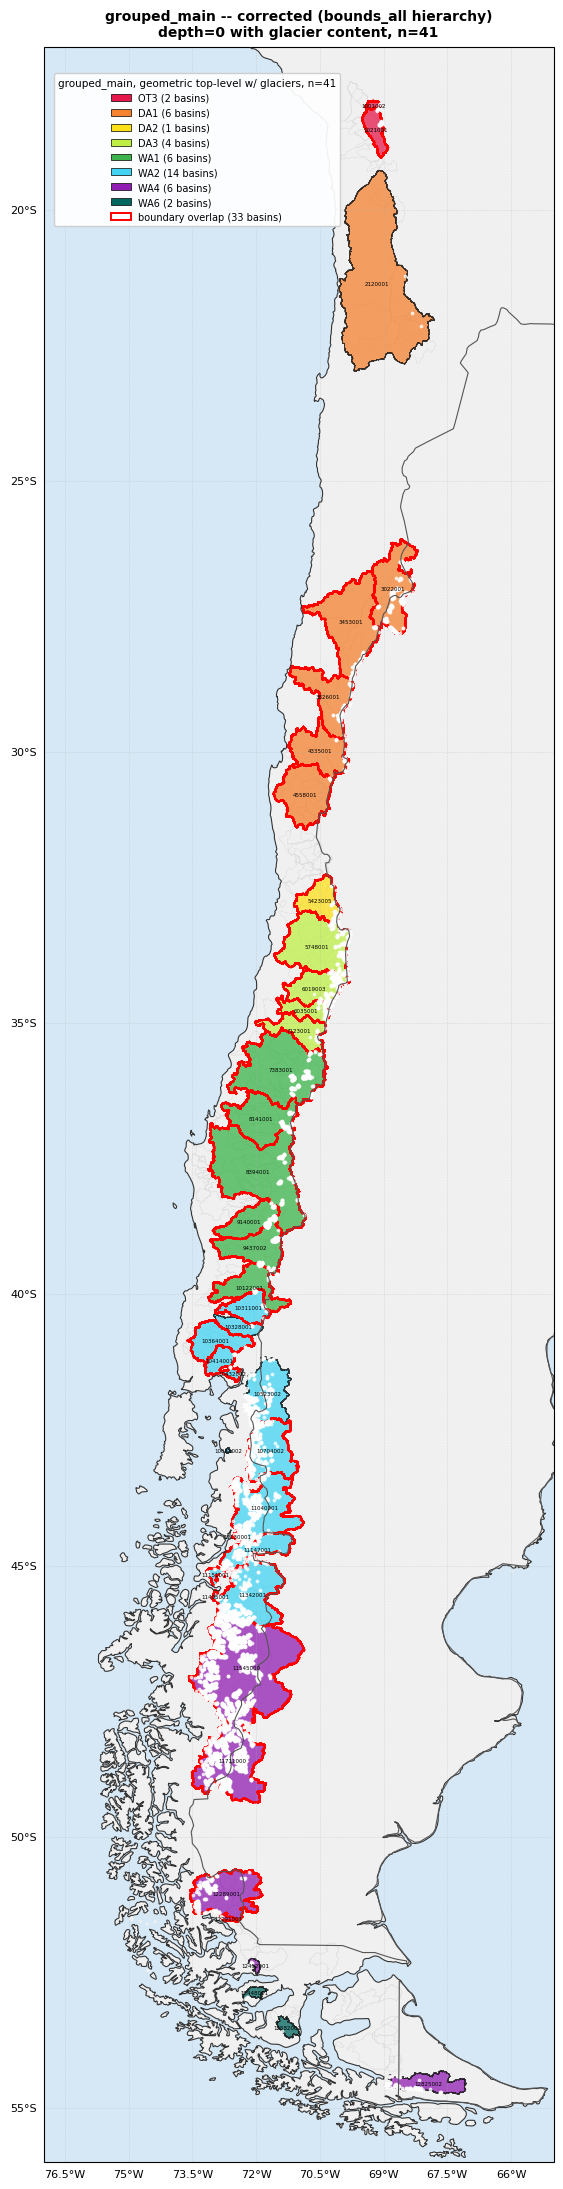

Saved: /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/grouped_main_v2_visual_check.png


In [6]:
cluster_colors = {
    'OT3': '#e6194b', 'DA1': '#f58231', 'DA2': '#ffe119', 'DA3': '#bfef45',
    'WA1': '#3cb44b', 'WA2': '#42d4f4', 'WA3': '#4363d8', 'WA4': '#911eb4',
    'WA5': '#f032e6', 'WA6': '#01665e',
}

# ── Visual check: grouped_main (41 basins), overlaps highlighted ──────────
main41 = bounds_all[bounds_all['gauge_id'].isin(df_glacierized_major['gauge_id'])].copy()
main41 = main41.merge(df_glacierized_major[['gauge_id','total_glacier_area_km2']],
                       on='gauge_id', how='left')

# assign dominant cluster per basin (same logic as before)
joined41 = gpd.sjoin(gdf_rgi[['RGIId','Cluster','geometry']],
                      main41[['gauge_id','geometry']], how='inner', predicate='within')
dominant_cluster41 = (joined41.groupby('gauge_id')['Cluster']
                       .agg(lambda x: x.value_counts().index[0]).reset_index()
                       .rename(columns={'Cluster':'cluster'}))
main41 = main41.merge(dominant_cluster41, on='gauge_id', how='left')

overlap_gauge_ids = set(df_overlaps['gauge_i']) | set(df_overlaps['gauge_j'])

fig = plt.figure(figsize=(10, 22))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([-77, -65, -56, -17], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.OCEAN, facecolor='#d6e8f5', zorder=0)
ax.add_feature(cfeature.LAND, facecolor='#f0f0f0', zorder=0)
bounds_all.plot(ax=ax, facecolor='none', edgecolor='#dddddd', linewidth=0.25, zorder=1)

# sort by area descending so smaller basins draw on top and stay visible
main41 = main41.sort_values('area_km2', ascending=False)

for cl, color in cluster_colors.items():
    subset = main41[main41['cluster']==cl]
    if len(subset):
        subset.plot(ax=ax, facecolor=color, edgecolor='k', linewidth=0.6, alpha=0.75, zorder=2)
unassigned = main41[main41['cluster'].isna()]
if len(unassigned):
    unassigned.plot(ax=ax, facecolor='#cccccc', edgecolor='k', linewidth=0.4, alpha=0.6, zorder=2)

# outline the basins involved in any overlap pair, in red, on top
flagged = main41[main41['gauge_id'].isin(overlap_gauge_ids)]
if len(flagged):
    flagged.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=1.4, zorder=3)

glaciers_in = gpd.sjoin(gdf_rgi, main41[['gauge_id','geometry']], how='inner', predicate='within')
ax.scatter(glaciers_in.CenLon, glaciers_in.CenLat, s=3, c='white', alpha=0.7, zorder=4,
           transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor='#333333', zorder=5)
if has_borders:
    arg.plot(ax=ax, facecolor='none', edgecolor='#555555', linewidth=0.8, zorder=5,
             transform=ccrs.PlateCarree())

gl = ax.gridlines(draw_labels=True, linewidth=0.4, alpha=0.4, linestyle='--')
gl.top_labels = False; gl.right_labels = False
gl.xlabel_style = {'size': 8}; gl.ylabel_style = {'size': 8}

for _, row in main41.iterrows():
    centroid = row.geometry.centroid
    name = str(row.get('gauge_nam', row['gauge_id']))[:18]
    ax.text(centroid.x, centroid.y, name, fontsize=4, ha='center', va='center',
            color='k', zorder=6, transform=ccrs.PlateCarree())

legend_handles = []
for cl in cluster_colors:
    n = (main41['cluster']==cl).sum()
    if n:
        legend_handles.append(Patch(facecolor=cluster_colors[cl], edgecolor='k',
                                     linewidth=0.5, label=f'{cl} ({n} basins)'))
legend_handles.append(Patch(facecolor='none', edgecolor='red', linewidth=1.4,
                             label=f'boundary overlap ({len(flagged)} basins)'))
ax.legend(handles=legend_handles, loc='upper left', fontsize=7, framealpha=0.93,
          title=f'grouped_main, geometric top-level w/ glaciers, n={len(main41)}',
          title_fontsize=7.5, bbox_to_anchor=(0.01,0.99))
ax.set_title(f'grouped_main -- corrected (bounds_all hierarchy)\n'
             f'depth=0 with glacier content, n={len(main41)}',
             fontsize=10, fontweight='bold', pad=8)
plt.tight_layout()
out = f'{OUTPUT_ROOT}/grouped_main_v2_visual_check.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')

In [7]:
df_glacierized_major['glacier_pct'] = (df_glacierized_major['total_glacier_area_km2'] /
                                        df_glacierized_major['area_km2'] * 100)

leaf_stats = bounds_utm[bounds_utm['gauge_id'].isin(leaf_glacierized_ids_v3)][['gauge_id','area_km2']].copy()
leaf_stats['glacier_area_km2'] = leaf_stats['gauge_id'].map(glacier_area_by_gauge)
leaf_stats['glacier_pct'] = leaf_stats['glacier_area_km2'] / leaf_stats['area_km2'] * 100

print('grouped_main (41 basins, glacier area aggregated over nested children):')
print(df_glacierized_major['glacier_pct'].describe())
print()
print('leaf_only (103 basins, own area only):')
print(leaf_stats['glacier_pct'].describe())

grouped_main (41 basins, glacier area aggregated over nested children):
count    41.000000
mean      4.800536
std       8.681652
min       0.005539
25%       0.254078
50%       1.599058
75%       3.822012
max      36.549187
Name: glacier_pct, dtype: float64

leaf_only (103 basins, own area only):
count    103.000000
mean       3.242272
std        7.154818
min        0.002985
25%        0.134728
50%        0.892236
75%        3.136637
max       52.877589
Name: glacier_pct, dtype: float64


In [8]:
true_unique_glacier_area = rgi_bna['Area'].sum()  # every RGI glacier, counted once
summed_across_all_gauges = sum(glacier_area_by_gauge.values())

print(f'True unique glacier area (RGI, region-wide): {true_unique_glacier_area:.1f} km2')
print(f'Sum of glacier_area_by_gauge across all {len(glacier_area_by_gauge)} gauges: {summed_across_all_gauges:.1f} km2')
print(f'Ratio: {summed_across_all_gauges/true_unique_glacier_area:.2f}x')

True unique glacier area (RGI, region-wide): 27499.4 km2
Sum of glacier_area_by_gauge across all 266 gauges: 20013.9 km2
Ratio: 0.73x


## 3. Leaf-level & major-basin identification

In [9]:
# ── Top-level ("major") basins, and which of them contain glaciers ─────────
df_top_level = df_hierarchy[df_hierarchy['depth'] == 0].copy()
df_top_level['contained_gauge_ids'] = df_top_level['gauge_id'].map(
    lambda g: contained_map.get(g, []))
df_top_level['n_nested_basins'] = df_top_level['contained_gauge_ids'].apply(len)

records = []
for _, row in df_top_level.iterrows():
    major_id = row['gauge_id']
    nested_ids = row['contained_gauge_ids']
    total_glacier_area = (glacier_area_by_gauge.get(major_id, 0) +
                          sum(glacier_area_by_gauge.get(nid, 0) for nid in nested_ids))
    n_glacierized_nested = sum(1 for nid in nested_ids
                               if glacier_area_by_gauge.get(nid, 0) > 0)
    if total_glacier_area > 0:
        records.append({
            'gauge_id': major_id, 'gauge_name': row['gauge_name'],
            'area_km2': row['area_km2'], 'n_nested_basins': row['n_nested_basins'],
            'n_glacierized_nested': n_glacierized_nested,
            'total_glacier_area_km2': total_glacier_area,
        })
df_glacierized_major = pd.DataFrame(records).sort_values(
    'total_glacier_area_km2', ascending=False)

# ── Leaf-level glacierized basins: a basin qualifies if NONE of its
# contained sub-basins is ALSO glacierized (avoids double-counting) ────────
leaf_glacierized_ids_v3 = set()
for gid in all_glacierized_basins_ever:
    glacierized_children = [c for c in contained_map.get(gid, [])
                             if glacier_area_by_gauge.get(c, 0) > 0]
    if len(glacierized_children) == 0:
        leaf_glacierized_ids_v3.add(gid)

print(f'Top-level basins: {len(df_top_level)}')
print(f'Top-level basins containing glaciers: {len(df_glacierized_major)}')
print(f'Leaf-level glacierized basins: {len(leaf_glacierized_ids_v3)}')


Top-level basins: 101
Top-level basins containing glaciers: 41
Leaf-level glacierized basins: 103


In [10]:
# ── Known gauge-coverage gap: glaciers here can't be assigned to any
# streamflow basin and are excluded from all streamflow-fraction analyses ──
gap_glaciers = rgi_bna[(rgi_bna['CenLat'] <= -23) & (rgi_bna['CenLat'] >= -27)]
print(f'Glaciers in the -23 to -27 gauge-coverage gap: {len(gap_glaciers)}')
print(f'Total area: {gap_glaciers["Area"].sum():.2f} km2')


Glaciers in the -23 to -27 gauge-coverage gap: 65
Total area: 18.14 km2


## 4. Data quality: glacier region coverage, anomalous gauges, runoff>Q by depth

In [11]:
# ── Combined glacier polygons, RGI regions 16+17 ────────────────────────────
# Region 16 must be included or 32 glaciers physically inside Chile
# (29 of which are part of the OGGM pipeline via RGI_BNA_Clusters.csv)
# are silently excluded.
rgi_r17_path = utils.get_rgi_region_file('17', version='62')
rgi_r16_path = utils.get_rgi_region_file('16', version='62')
rgi_r17 = gpd.read_file(rgi_r17_path).to_crs(epsg=4326)
rgi_r16 = gpd.read_file(rgi_r16_path).to_crs(epsg=4326)
rgi_r16_chile = gpd.clip(rgi_r16, chile) if has_borders else rgi_r16
rgi_geoms_combined = pd.concat([rgi_r17, rgi_r16_chile], ignore_index=True)

print(f'Region 17: {len(rgi_r17)} glaciers')
print(f'Region 16 (clipped to Chile): {len(rgi_r16_chile)} glaciers')
print(f'Combined: {len(rgi_geoms_combined)} glaciers')


Region 17: 15908 glaciers
Region 16 (clipped to Chile): 32 glaciers
Combined: 15940 glaciers


In [12]:
# ── Data quality flagging: basins where simulated glacier runoff exceeds
# measured streamflow in a large fraction of months ─────────────────────────
def check_runoff_exceeds_q(gid, dataset='CR2MET'):
    res = RESULTS[dataset].get(gid)
    if res is None:
        return None
    m = res['monthly'].copy()
    m = m[m['q_m3_mon'] > 0].dropna(subset=['glacier_runoff_m3','q_m3_mon'])
    if len(m) == 0:
        return None
    m['pct'] = m['glacier_runoff_m3'] / m['q_m3_mon'] * 100
    return {
        'n_months': len(m),
        'n_months_over_100': (m['pct'] > 100).sum(),
        'pct_months_over_100': (m['pct'] > 100).mean() * 100,
        'median_pct': m['pct'].median(),
        'max_pct': m['pct'].max(),
    }

name_by_id = df_hierarchy.set_index('gauge_id')['gauge_name'].to_dict()
quality_records = []
for gid in all_glacierized_basins_ever:
    if gid not in RESULTS['CR2MET']:
        continue
    result = check_runoff_exceeds_q(gid)
    if result is None:
        continue
    quality_records.append({'gauge_id': gid, 'gauge_name': name_by_id.get(gid, '?'), **result})

df_quality = pd.DataFrame(quality_records).sort_values('pct_months_over_100', ascending=False)

QUALITY_FLAG_THRESHOLD = 20.0
flagged_basins = set(
    df_quality[df_quality['pct_months_over_100'] > QUALITY_FLAG_THRESHOLD]['gauge_id'])
print(f'Basins flagged (>{QUALITY_FLAG_THRESHOLD}% of months with runoff>Q): {len(flagged_basins)}')
df_quality.to_csv(f'{OUTPUT_ROOT}/basin_data_quality_flags.csv', index=False)
print(df_quality.head(15).to_string(index=False))


Basins flagged (>20.0% of months with runoff>Q): 9
gauge_id                                  gauge_name  n_months  n_months_over_100  pct_months_over_100   median_pct      max_pct
 7317003                 Rio Melado En Zona De Presa       199                107            53.768844 2.154615e+02 69191.958960
 5406001                    Rio Colorado En Colorado       206                 87            42.233010 5.675125e+01 27263.759403
 6008005    Rio Cachapoal En Pte Termas De Cauquenes       190                 65            34.210526 6.519751e+01  2603.588778
 7321002                      Rio Maule En Armerillo       197                 65            32.994924 1.324780e+01   849.418806
 7306001 Rio Cipreses En Dasague Laguna La Invernada       172                 48            27.906977 8.594820e+00   353.659743
 5706001       Rio Olivares Antes Junta Rio Colorado       222                 59            26.576577 6.590002e+00   991.761563
 3022001                     Rio La Ola En Ver

### Anomalous gauge investigation: Maipo system

Maipo's leaf-summed glacier fraction occasionally exceeded 100% (up to 555%
in one month) when combining the three leaf-level gauges feeding it. Traced
to two specific gauges — Rio Volcan En Queltehues (`5702001`) and Rio
Olivares Antes Junta Rio Colorado (`5706001`) — where simulated glacier
runoff exceeds measured streamflow **at that single gauge** (no
basin-summing involved) in a large fraction of months, **consistently
across all 3 climate datasets** (ruling out a melt-simulation artifact tied
to one dataset specifically). Estero Yerba Loca (`5721001`), the third
Maipo-system leaf gauge, shows no such issue (0 of 223 months over 100%).

**Conclusion:** the CAMELS streamflow records at these two gauges are
suspect, not the glacier melt simulation. Flagged for Alexis to review the
raw Q record at these two gauges specifically — status: pending.

In [13]:
for gid in ['5702001', '5706001', '5721001']:
    for ds in ['CR2MET', 'ERA5', 'CRU']:
        res = RESULTS[ds].get(gid)
        if res is None:
            continue
        m = res['monthly'].copy()
        m = m[m['q_m3_mon'] > 0]
        m['frac_pct'] = m['glacier_runoff_m3'] / m['q_m3_mon'] * 100
        n_over_100 = (m['frac_pct'] > 100).sum()
        print(f'{gid} / {ds}: {n_over_100} of {len(m)} months over 100%, '
              f'median={m["frac_pct"].median():.1f}%')

# Manual exclusion pending Alexis's review of the raw Q record
MANUALLY_EXCLUDED_GAUGES = {'5702001', '5706001'}
leaf_ids_final_clean = leaf_glacierized_ids_v3 - MANUALLY_EXCLUDED_GAUGES
print(f'\nLeaf basins before exclusion: {len(leaf_glacierized_ids_v3)}')
print(f'Leaf basins after excluding flagged gauges: {len(leaf_ids_final_clean)}')
print('STATUS: pending Alexis review of raw Q record at 5702001 and 5706001')


5702001 / CR2MET: 41 of 224 months over 100%, median=37.9%
5702001 / ERA5: 40 of 224 months over 100%, median=0.3%
5702001 / CRU: 25 of 224 months over 100%, median=20.0%
5706001 / CR2MET: 59 of 222 months over 100%, median=6.6%
5706001 / ERA5: 55 of 222 months over 100%, median=0.0%
5706001 / CRU: 59 of 222 months over 100%, median=0.9%
5721001 / CR2MET: 0 of 223 months over 100%, median=3.3%
5721001 / ERA5: 1 of 223 months over 100%, median=0.0%
5721001 / CRU: 0 of 223 months over 100%, median=0.0%

Leaf basins before exclusion: 103
Leaf basins after excluding flagged gauges: 101
STATUS: pending Alexis review of raw Q record at 5702001 and 5706001


## 5. Dilution visualization: glacier fraction vs. position in hierarchy

In [14]:
def basin_fraction(gid, dataset='CR2MET', months=None):
    res = RESULTS[dataset].get(gid)
    if res is None:
        return np.nan
    m = res['monthly'].copy()
    if months is not None:
        m = m[m['month'].isin(months)]
    m = m[m['q_m3_mon'] > 0].dropna(subset=['glacier_runoff_m3','q_m3_mon'])
    if len(m) == 0:
        return np.nan
    return (m['glacier_runoff_m3'].sum() / m['q_m3_mon'].sum()) * 100

chain_records = []
for leaf_gid in leaf_glacierized_ids_v3:
    if leaf_gid not in RESULTS['CR2MET']:
        continue
    chain = get_full_chain(leaf_gid, container_map, area_by_id)
    n_levels = len(chain)
    for depth_idx, gid in enumerate(chain):
        row = bounds_all[bounds_all['gauge_id']==gid]
        if len(row) == 0:
            continue
        chain_records.append({
            'leaf_gauge_id': leaf_gid,
            'chain_position': depth_idx, 'chain_length': n_levels,
            'gauge_id': gid, 'area_km2': row['area_km2'].values[0],
            'annual_fraction_pct': basin_fraction(gid),
            'leaf_flagged': leaf_gid in flagged_basins,
        })

df_chains = pd.DataFrame(chain_records)
df_chains['normalized_position'] = df_chains.apply(
    lambda row: row['chain_position']/(row['chain_length']-1) if row['chain_length']>1 else 0, axis=1)
df_chains.to_csv(f'{OUTPUT_ROOT}/basin_chain_fractions.csv', index=False)

n_nan = df_chains['annual_fraction_pct'].isna().sum()
print(f'Chain records built: {len(df_chains)} across {len(leaf_glacierized_ids_v3)} leaf chains')
print(f'NaN fraction (basin not in RESULTS -- non-glacierized pass-through basin never simulated): '
      f'{n_nan} of {len(df_chains)} ({n_nan/len(df_chains)*100:.1f}%)')


Chain records built: 239 across 103 leaf chains
NaN fraction (basin not in RESULTS -- non-glacierized pass-through basin never simulated): 72 of 239 (30.1%)


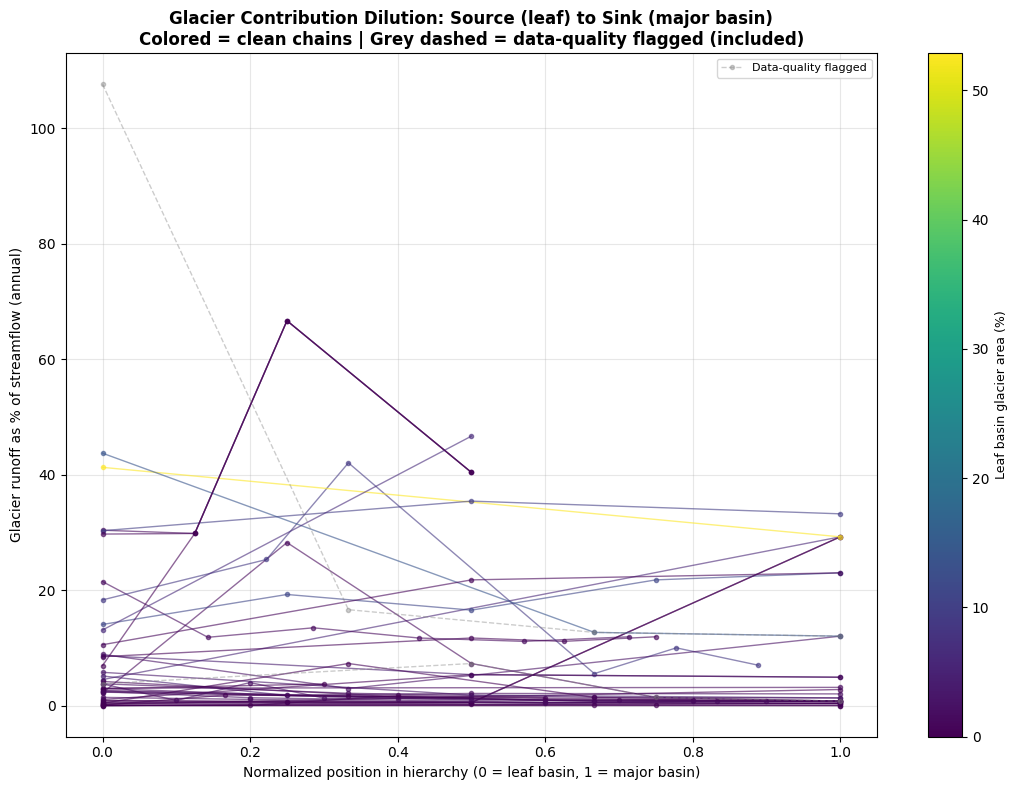

In [15]:
fig, ax = plt.subplots(figsize=(11, 8))

clean_chains = df_chains[~df_chains['leaf_flagged']]
flagged_chains = df_chains[df_chains['leaf_flagged']]

leaf_glacier_pct = {
    gid: glacier_area_by_gauge.get(gid, 0) /
         bounds_all[bounds_all['gauge_id']==gid]['area_km2'].values[0] * 100
    for gid in leaf_glacierized_ids_v3
    if len(bounds_all[bounds_all['gauge_id']==gid]) > 0
}
max_pct = max(leaf_glacier_pct.values()) if leaf_glacier_pct else 1
cmap = plt.cm.viridis
norm = Normalize(vmin=0, vmax=max_pct)

for leaf_gid in clean_chains['leaf_gauge_id'].unique():
    sub = clean_chains[clean_chains['leaf_gauge_id']==leaf_gid].sort_values('normalized_position')
    sub = sub.dropna(subset=['annual_fraction_pct'])
    if len(sub) < 2:
        continue
    color = cmap(norm(leaf_glacier_pct.get(leaf_gid, 0)))
    ax.plot(sub['normalized_position'], sub['annual_fraction_pct'],
           'o-', color=color, alpha=0.6, lw=1, ms=3)

first_flagged = True
for leaf_gid in flagged_chains['leaf_gauge_id'].unique():
    sub = df_chains[df_chains['leaf_gauge_id']==leaf_gid].sort_values('normalized_position')
    sub = sub.dropna(subset=['annual_fraction_pct'])
    if len(sub) < 2:
        continue
    ax.plot(sub['normalized_position'], sub['annual_fraction_pct'],
           'o--', color='grey', alpha=0.4, lw=1, ms=3,
           label='Data-quality flagged' if first_flagged else None)
    first_flagged = False

sm = ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Leaf basin glacier area (%)', fontsize=9)

ax.set_xlabel('Normalized position in hierarchy (0 = leaf basin, 1 = major basin)', fontsize=10)
ax.set_ylabel('Glacier runoff as % of streamflow (annual)', fontsize=10)
ax.set_title('Glacier Contribution Dilution: Source (leaf) to Sink (major basin)\n'
             'Colored = clean chains | Grey dashed = data-quality flagged (included)',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/dilution_normalized.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Leaf-summed glacier fraction per major basin (annual / JFM / megadrought)

In [16]:
def compute_leaf_fraction(major_id, leaf_ids_set, months=None, years=None):
    """Sum glacier runoff and streamflow across the leaf-level glacierized
    sub-basins within major_id (NOT the major basin's own Q). A month is only
    included if ALL contributing leaf gauges have valid, non-negative Q that
    month, so the combined total is consistent across time."""
    nested_ids = contained_map.get(major_id, [])
    leaf_ids_in_major = [nid for nid in nested_ids if nid in leaf_ids_set]
    if major_id in leaf_ids_set:
        leaf_ids_in_major.append(major_id)
    if not leaf_ids_in_major:
        return np.nan, 0

    glac_frames, q_frames = [], []
    for leaf_id in leaf_ids_in_major:
        res = RESULTS['CR2MET'].get(leaf_id)
        if res is None:
            continue
        m = res['monthly'].copy()
        if years is not None:
            m = m[m['year'].isin(years)]
        if months is not None:
            m = m[m['month'].isin(months)]
        m = m.set_index(['year','month'])
        glac_frames.append(m[['glacier_runoff_m3']].rename(
            columns={'glacier_runoff_m3': f'glac_{leaf_id}'}))
        q_frames.append(m[['q_m3_mon']].rename(
            columns={'q_m3_mon': f'q_{leaf_id}'}))

    if not glac_frames:
        return np.nan, 0

    glac_wide = pd.concat(glac_frames, axis=1)
    q_wide = pd.concat(q_frames, axis=1)
    q_complete_mask = q_wide.notna().all(axis=1) & (q_wide >= 0).all(axis=1)

    q_summed = q_wide[q_complete_mask].sum(axis=1)
    glac_summed = glac_wide[q_complete_mask].sum(axis=1)

    valid = q_summed > 0
    if valid.sum() == 0:
        return np.nan, 0

    frac = (glac_summed[valid].sum() / q_summed[valid].sum()) * 100
    return frac, len(leaf_ids_in_major)

JFM_MONTHS = [1, 2, 3]
MEGADROUGHT_YEARS = list(range(2010, 2020))

scope_results = {}
for _, major_row in df_glacierized_major.iterrows():
    mid = major_row['gauge_id']
    frac_annual, n_leaf = compute_leaf_fraction(mid, leaf_ids_final_clean, months=None, years=None)
    frac_jfm, _ = compute_leaf_fraction(mid, leaf_ids_final_clean, months=JFM_MONTHS, years=None)
    frac_drought, _ = compute_leaf_fraction(mid, leaf_ids_final_clean, months=None, years=MEGADROUGHT_YEARS)
    scope_results[mid] = {'annual_pct': frac_annual, 'jfm_pct': frac_jfm,
                           'drought_pct': frac_drought, 'n_leaf': n_leaf}

n_with_result = sum(1 for r in scope_results.values() if not np.isnan(r['annual_pct']))
print(f'scope_results built for {len(scope_results)} major basins')
print(f'Major basins with a computed annual glacier fraction: {n_with_result} of {len(df_glacierized_major)}')
print('(remainder lack any completeness-passing leaf basin)')

df_scope = pd.DataFrame(scope_results).T
df_scope.index.name = 'gauge_id'
df_scope = df_scope.reset_index().merge(
    df_glacierized_major[['gauge_id','gauge_name','area_km2']], on='gauge_id', how='left')
df_scope.to_csv(f'{OUTPUT_ROOT}/major_basin_leaf_summed_fractions.csv', index=False)
print(f'Saved: {OUTPUT_ROOT}/major_basin_leaf_summed_fractions.csv')
print(df_scope.sort_values('annual_pct', ascending=False).head(10).to_string(index=False))


scope_results built for 41 major basins
Major basins with a computed annual glacier fraction: 29 of 41
(remainder lack any completeness-passing leaf basin)
Saved: /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/major_basin_leaf_summed_fractions.csv
gauge_id  annual_pct   jfm_pct  drought_pct  n_leaf                            gauge_name     area_km2
11711000   30.298306 51.442296    31.723490     1.0      Rio Pascua Ante Junta Rio Quetru 14121.323846
12289001   28.419715 27.740072    28.350342     7.0          Rio Serrano En Desembocadura  8574.609649
 3453001   25.042433 74.766019    36.478683     3.0              Rio Copiapo En Angostura 18549.908986
 5423005   18.319143 33.644291    24.945164     3.0         Rio Aconcagua En Panamericana  5647.991589
11545000   13.734004 29.443751    12.797760     6.0                  Rio Baker Bajo ÑAdis 27402.563558
 3826001   13.713061 36.075007    17.900064     2.0             Rio Huasco En Huasco Bajo  9739.814913
 5748001    8.888796 17.358

### Candidate intermediate sub-basins ("El Manzano tier")

Nested basins that themselves aggregate 2+ smaller basins (e.g. El Manzano
sits between Cabimbao and the Maipo system's leaves). Exported for Alexis
to confirm which represent recognized hydrological sub-basins vs. incidental
nested gauges.

In [17]:
intermediate_candidates = []
for _, major_row in df_glacierized_major.iterrows():
    major_id = major_row['gauge_id']
    nested_ids = contained_map.get(major_id, [])
    for nid in nested_ids:
        n_children = len(contained_map.get(nid, []))
        if n_children >= 2:
            glac_area = glacier_area_by_gauge.get(nid, 0)
            if glac_area > 0:
                name_row = bounds_all[bounds_all['gauge_id']==nid]
                if len(name_row) == 0:
                    continue
                intermediate_candidates.append({
                    'major_id': major_id, 'major_name': major_row['gauge_name'],
                    'candidate_id': nid, 'candidate_name': name_row['gauge_name'].values[0],
                    'n_children': n_children, 'glacier_area_km2': glac_area,
                })

df_intermediate = pd.DataFrame(intermediate_candidates)
print(f'Candidate intermediate sub-basin gauges found: {len(df_intermediate)}')

export_path = f'{OUTPUT_ROOT}/intermediate_subbasin_candidates_for_Ale.csv'
df_intermediate.sort_values(['major_id','n_children'], ascending=[True,False]).to_csv(
    export_path, index=False)
print(f'Saved: {export_path}')


Candidate intermediate sub-basin gauges found: 104
Saved: /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/intermediate_subbasin_candidates_for_Ale.csv


## 7. Deliverables for Alexis

### 7a. `main_basins_for_alexis.shp` export

Implements Alexis's workflow, now using `basin_hierarchy_utils` instead of
the unreliable `Camels_jerarquia.shp` field:
- Step 1: Find CAMELS polygons that contain at least one RGI glacier centroid
- Step 2: Keep only geometrically top-level (depth=0) basins per river system
- Step 3: (Visual check in QGIS/ArcGIS — do manually after export)
- Step 4: Compute basin area and glacier area, apply 1% minimum threshold

In [18]:
OUT_PATH_ALE = f'{OUTPUT_ROOT}/main_basins_for_alexis.shp'
GLAC_THRESHOLD_PCT = 1.0  # Alexis recommends 1% minimum glacier cover

joined = gpd.sjoin(gdf_rgi, bounds_all, how='inner', predicate='within')
glacierized_gauge_ids_export = set(joined['gauge_id'].unique())
glacier_stats = (joined.groupby('gauge_id')
                 .agg(n_glaciers=('RGIId','count'), glacier_area=('Area','sum'),
                      clusters=('Cluster', lambda x: list(x.unique())))
                 .reset_index())

main_basins_export = bounds_all[bounds_all['gauge_id'].isin(
    df_hierarchy[df_hierarchy['depth']==0]['gauge_id'])].copy()
main_glacierized_export = main_basins_export[
    main_basins_export['gauge_id'].isin(glacierized_gauge_ids_export)].copy()
main_glacierized_export = main_glacierized_export.merge(
    df_hierarchy[['gauge_id','depth']], on='gauge_id', how='left')

main_utm_export = main_glacierized_export.to_crs(epsg=32719)
main_utm_export['basin_area_km2'] = main_utm_export.geometry.area / 1e6
main_utm_export = main_utm_export.merge(glacier_stats, on='gauge_id', how='left')
main_utm_export['glacier_area_km2'] = main_utm_export['glacier_area'].fillna(0)
main_utm_export['glacier_pct'] = (main_utm_export['glacier_area_km2'] /
                                   main_utm_export['basin_area_km2'] * 100)

before = len(main_utm_export)
main_final = main_utm_export[main_utm_export['glacier_pct'] >= GLAC_THRESHOLD_PCT].copy()
after = len(main_final)
print(f'Geometrically top-level basins with glaciers: {before}')
print(f'After {GLAC_THRESHOLD_PCT}% threshold: {after} ({before-after} removed)')

main_export = main_final.to_crs(epsg=4326)
keep_cols = ['gauge_id','gauge_name','depth','n_glaciers','basin_area_km2',
             'glacier_area_km2','glacier_pct','geometry']
keep_cols = [c for c in keep_cols if c in main_export.columns]
main_export = main_export[keep_cols]
main_export.to_file(OUT_PATH_ALE)
print(f'Saved: {OUT_PATH_ALE}')
print(f'Total glacier area: {main_final["glacier_area_km2"].sum():.1f} km2')
print(f'Total basin area:   {main_final["basin_area_km2"].sum():.1f} km2')


Geometrically top-level basins with glaciers: 41
After 1.0% threshold: 15 (26 removed)
Saved: /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/main_basins_for_alexis.shp
Total glacier area: 6859.2 km2
Total basin area:   130359.3 km2


### 7b. Visual check of `main_basins_for_alexis.shp`

### 7c. Major-basin map with glacier-fraction pie-chart pullouts

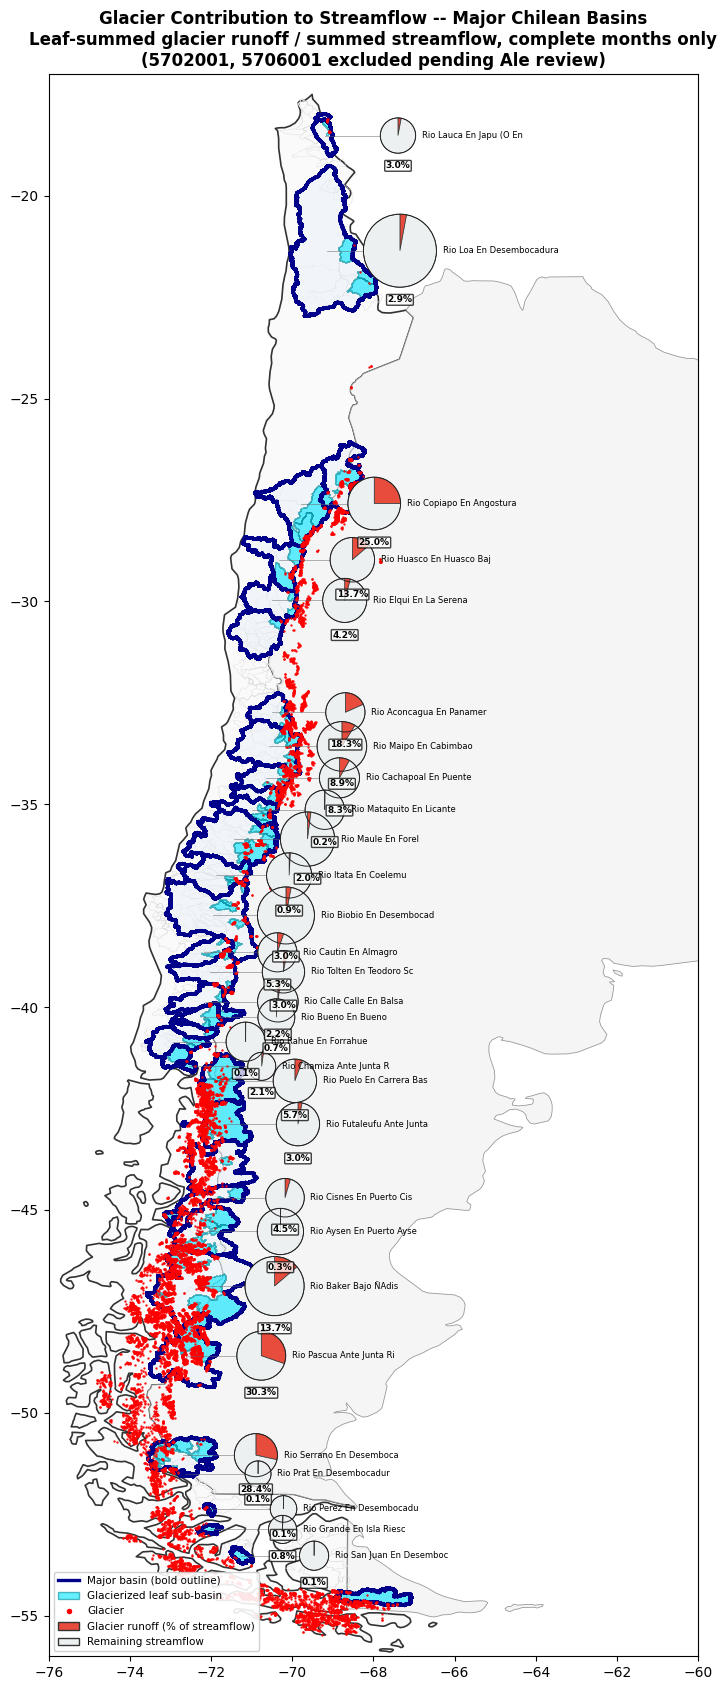

In [19]:
fig, ax = plt.subplots(figsize=(13, 17))
if has_borders:
    chile.plot(ax=ax, facecolor='#fafafa', edgecolor='#333333', linewidth=1.2, zorder=0)
    arg.plot(ax=ax, facecolor='#f5f5f5', edgecolor='#999999', linewidth=0.6, zorder=0)

bounds_all.plot(ax=ax, facecolor='none', edgecolor='#dddddd', linewidth=0.2, zorder=1)

glacierized_ids = set(df_glacierized_major['gauge_id'])
bounds_all[bounds_all['gauge_id'].isin(glacierized_ids)].plot(
    ax=ax, facecolor='#eaf2fa', alpha=0.5, edgecolor='none', zorder=2)
bounds_all[bounds_all['gauge_id'].isin(glacierized_ids)].plot(
    ax=ax, facecolor='none', edgecolor='#00008b', linewidth=2.4, zorder=4)
bounds_all[bounds_all['gauge_id'].isin(leaf_glacierized_ids_v3)].plot(
    ax=ax, facecolor='#00e5ff', alpha=0.6, edgecolor='#008b99', linewidth=0.7, zorder=3)

glacier_centroids_proj = rgi_geoms_combined.to_crs(epsg=32719).geometry.centroid
glacier_centroids = gpd.GeoSeries(glacier_centroids_proj, crs=32719).to_crs(epsg=4326)
ax.scatter(glacier_centroids.x, glacier_centroids.y, color='#ff0000', s=0.5, zorder=5, alpha=0.9)

has_scope = [g for g, r in scope_results.items() if not np.isnan(r['annual_pct'])]
df_pie = df_glacierized_major[df_glacierized_major['gauge_id'].isin(has_scope)].copy()
df_pie['centroid'] = df_pie['gauge_id'].apply(
    lambda g: bounds_all[bounds_all['gauge_id']==g].geometry.centroid.values[0]
    if len(bounds_all[bounds_all['gauge_id']==g]) else None)
df_pie = df_pie[df_pie['centroid'].notna()]
df_pie['cen_lat'] = df_pie['centroid'].apply(lambda c: c.y)
df_pie['frac_pct'] = df_pie['gauge_id'].map(lambda g: scope_results[g]['annual_pct'])

area_max = df_pie['area_km2'].max()
CIRC_MAX, CIRC_MIN = 0.9, 0.28
def area_to_radius(area):
    return CIRC_MIN if area <= 0 else CIRC_MIN + (area/area_max)**0.5 * (CIRC_MAX-CIRC_MIN)

LABEL_OFFSET = 1.8
for _, row in df_pie.sort_values('cen_lat', ascending=False).iterrows():
    cx, cy = row['centroid'].x, row['centroid'].y
    label_x = cx + LABEL_OFFSET
    radius = area_to_radius(row['area_km2'])
    frac = row['frac_pct']
    ax.plot([cx, label_x], [cy, cy], color='#666666', lw=0.5, zorder=6, alpha=0.7)
    frac_clip = min(frac/100, 1.0)
    theta1 = 90
    for size, fc in [(frac_clip, '#e74c3c'), (1-frac_clip, '#ecf0f1')]:
        theta2 = theta1 - size*360
        ax.add_patch(Wedge((label_x, cy), radius, min(theta1,theta2), max(theta1,theta2),
                    facecolor=fc, edgecolor='#333333', lw=0.5, zorder=7))
        theta1 = theta2
    ax.add_patch(plt.Circle((label_x, cy), radius, facecolor='none',
                edgecolor='#222222', lw=0.7, zorder=8))
    ax.text(label_x, cy-radius-0.2, f'{frac:.1f}%', ha='center', va='top', fontsize=6.5,
            fontweight='bold', zorder=9,
            bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.75))
    ax.text(label_x+radius+0.15, cy, row['gauge_name'][:24], fontsize=6, va='center',
            ha='left', zorder=9)

legend_elements = [
    Line2D([0],[0], color='#00008b', lw=2.4, label='Major basin (bold outline)'),
    Patch(facecolor='#00e5ff', edgecolor='#008b99', alpha=0.6, label='Glacierized leaf sub-basin'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#ff0000', markersize=5, label='Glacier'),
    Patch(facecolor='#e74c3c', edgecolor='#333333', label='Glacier runoff (% of streamflow)'),
    Patch(facecolor='#ecf0f1', edgecolor='#333333', label='Remaining streamflow'),
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=7.5, framealpha=0.9)
ax.set_title('Glacier Contribution to Streamflow -- Major Chilean Basins\n'
             'Leaf-summed glacier runoff / summed streamflow, complete months only\n'
             '(5702001, 5706001 excluded pending Ale review)',
             fontsize=12, fontweight='bold')
ax.set_xlim(-76, -60); ax.set_ylim(-56, -17); ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/major_basins_pie_glacier_fraction_for_Ale.png',
            dpi=200, bbox_inches='tight')
plt.show()


## Status / open items for Alexis

- Confirm whether the `jerarquia` field in `Camels_jerarquia.shp` was ever
  meant to be populated with real hierarchy levels, or is a placeholder from
  the original ArcGIS export (email sent).
- Review the raw CAMELS Q record at gauges `5702001` (Rio Volcan En
  Queltehues) and `5706001` (Rio Olivares Antes Junta Rio Colorado) —
  glacier runoff exceeds measured streamflow in a large fraction of months
  at each gauge individually, consistently across CR2MET/ERA5/CRU,
  suggesting a streamflow record issue rather than a melt-simulation issue.
- Confirm which rows in `intermediate_subbasin_candidates_for_Ale.csv`
  represent recognized hydrological sub-basins (the "El Manzano tier") vs.
  incidental nested gauges.
- Decide whether a minimum glacier-area-to-basin-area threshold should be
  applied to `leaf_glacierized_ids_v3` for consistency with the main
  sub-basin analysis (which uses 0.1%) — currently unfiltered here.


# sept 24 final check: 

In [20]:
comparison_records = []
for _, major_row in df_glacierized_major.iterrows():
    mid = major_row['gauge_id']
    major_own_pct = basin_fraction(mid)  # Option A: major gauge's own RESULTS entry
    leaf_summed_pct = scope_results.get(mid, {}).get('annual_pct', np.nan)  # Option B
    n_leaf = scope_results.get(mid, {}).get('n_leaf', 0)
    comparison_records.append({
        'gauge_id': mid, 'gauge_name': major_row['gauge_name'],
        'area_km2': major_row['area_km2'], 'n_leaf': n_leaf,
        'major_own_pct': major_own_pct,
        'leaf_summed_pct': leaf_summed_pct,
        'diff': leaf_summed_pct - major_own_pct if pd.notna(leaf_summed_pct) and pd.notna(major_own_pct) else np.nan,
    })

df_compare = pd.DataFrame(comparison_records).sort_values('leaf_summed_pct', ascending=False)
print(f'Both methods available: {df_compare[["major_own_pct","leaf_summed_pct"]].dropna().shape[0]} of {len(df_compare)} basins')
print(df_compare.to_string(index=False))

Both methods available: 20 of 41 basins
gauge_id                            gauge_name     area_km2  n_leaf  major_own_pct  leaf_summed_pct      diff
11711000      Rio Pascua Ante Junta Rio Quetru 14121.323846       1      33.218974        30.298306 -2.920668
12289001          Rio Serrano En Desembocadura  8574.609649       7      29.233939        28.419715 -0.814223
 3453001              Rio Copiapo En Angostura 18549.908986       3            NaN        25.042433       NaN
 5423005         Rio Aconcagua En Panamericana  5647.991589       3            NaN        18.319143       NaN
11545000                  Rio Baker Bajo ÑAdis 27402.563558       6      23.001860        13.734004 -9.267857
 3826001             Rio Huasco En Huasco Bajo  9739.814913       2            NaN        13.713061       NaN
 5748001                 Rio Maipo En Cabimbao 14914.808165       5      12.036833         8.888796 -3.148037
 6019003 Rio Cachapoal En Puente Arqueado (Ca)  6264.944146       4            N

In [21]:
# ── Cluster assignment for leaf basins ────────────────────────────────────
leaf_polys_all = bounds_all[bounds_all['gauge_id'].isin(leaf_ids)].copy()
joined_leaf = gpd.sjoin(gdf_rgi[['RGIId','Cluster','geometry']],
                         leaf_polys_all[['gauge_id','geometry']], how='inner', predicate='within')
dominant_cluster_leaf = (joined_leaf.groupby('gauge_id')['Cluster']
                          .agg(lambda x: x.value_counts().index[0]).reset_index()
                          .rename(columns={'Cluster':'cluster'}))
leaf_cluster_by_gauge = dominant_cluster_leaf.set_index('gauge_id')['cluster'].to_dict()

# ── Leaf (individual), CR2MET ─────────────────────────────────────────────
df_leaf_cr2met = pd.DataFrame([
    {'gauge_id': g, 'cluster': leaf_cluster_by_gauge.get(g, 'unassigned'),
     'pct': basin_fraction(g, dataset='CR2MET')}
    for g in leaf_ids
])

# ── Major (own) and Leaf grouped, CR2MET -- from df_full_compare ──────────
df_major_cr2met = df_full_compare[df_full_compare['dataset']=='CR2MET'].copy()

summary_leaf = df_leaf_cr2met.groupby('cluster')['pct'].agg(n_valid='count', mean='mean', median='median').reset_index()
summary_grouped = df_major_cr2met.groupby('cluster')['leaf_summed_pct'].agg(n_valid='count', mean='mean', median='median').reset_index()
summary_major = df_major_cr2met.groupby('cluster')['major_own_pct'].agg(n_valid='count', mean='mean', median='median').reset_index()

# ── Table-building helpers ──────────────────────────────────────────────────
cluster_order = ['OT3','DA1','DA2','DA3','WA1','WA2','WA3','WA4','WA5','WA6']

def prep(df_s, value_col_map=None):
    d = df_s.copy()
    d['cluster'] = pd.Categorical(d['cluster'], categories=cluster_order, ordered=True)
    d = d.sort_values('cluster').reset_index(drop=True)
    return d

def make_table_data(df_s):
    rows = []
    for _, row in df_s.iterrows():
        n = '-' if pd.isna(row['n_valid']) else f'{int(row["n_valid"])}'
        mean = '-' if pd.isna(row['mean']) else f'{row["mean"]:.1f}%'
        median = '-' if pd.isna(row['median']) else f'{row["median"]:.1f}%'
        rows.append([row['cluster'], n, mean, median])
    return rows

NameError: name 'leaf_ids' is not defined

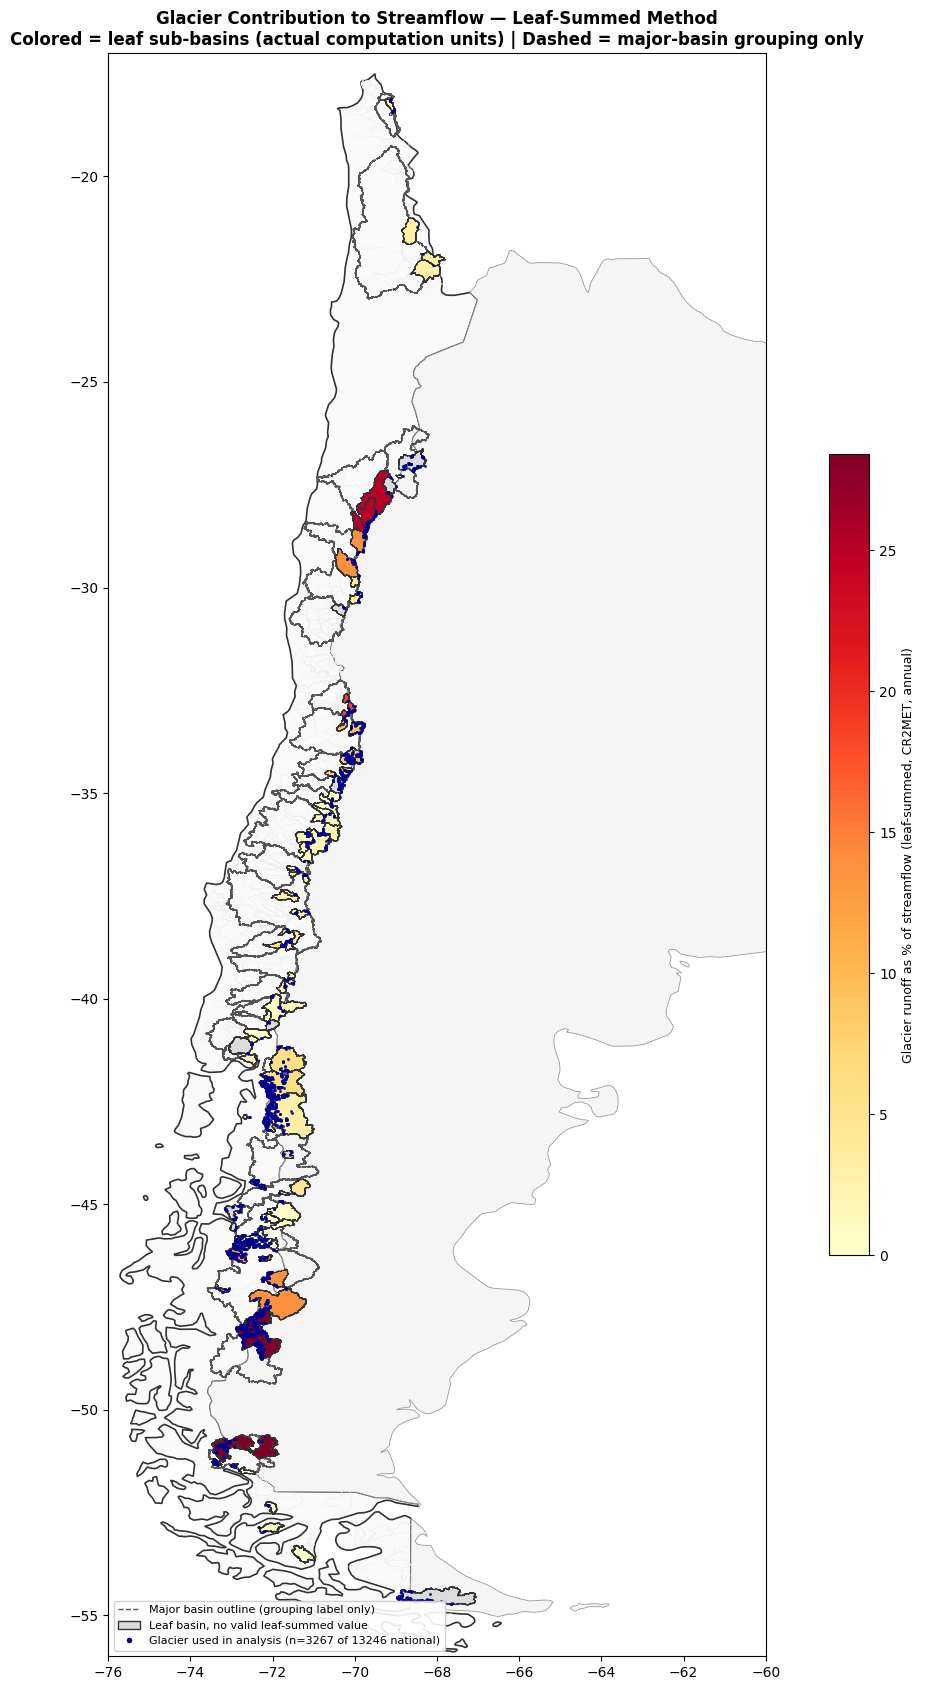

In [ ]:
# ── Leaf basins actually used in the leaf-summed calc, and which major group they belong to ──
leaf_to_major = {}
for _, major_row in df_glacierized_major.iterrows():
    mid = major_row['gauge_id']
    nested_ids = contained_map.get(mid, [])
    leaf_here = [nid for nid in nested_ids if nid in leaf_ids_final_clean]
    if mid in leaf_ids_final_clean:
        leaf_here.append(mid)
    for lid in leaf_here:
        leaf_to_major[lid] = mid

leaf_polys = bounds_all[bounds_all['gauge_id'].isin(leaf_to_major.keys())].copy()
leaf_polys['major_id'] = leaf_polys['gauge_id'].map(leaf_to_major)
# leaf_cr2met already built in the prerequisite cell -- do not overwrite it here
leaf_polys = leaf_polys.merge(leaf_cr2met.rename(columns={'gauge_id':'major_id'}), on='major_id', how='left')

fig, ax = plt.subplots(figsize=(13, 17))
if has_borders:
    chile.plot(ax=ax, facecolor='#fafafa', edgecolor='#333333', linewidth=1.2, zorder=0)
    arg.plot(ax=ax, facecolor='#f5f5f5', edgecolor='#999999', linewidth=0.6, zorder=0)
bounds_all.plot(ax=ax, facecolor='none', edgecolor='#eeeeee', linewidth=0.2, zorder=1)

bounds_all[bounds_all['gauge_id'].isin(df_glacierized_major['gauge_id'])].plot(
    ax=ax, facecolor='none', edgecolor='#555555', linewidth=1.0, linestyle='--', zorder=2)

has_val = leaf_polys[leaf_polys['leaf_summed_pct'].notna()]
no_val = leaf_polys[leaf_polys['leaf_summed_pct'].isna()]
vmax = has_val['leaf_summed_pct'].quantile(0.95)
frac_norm = Normalize(vmin=0, vmax=vmax)
frac_cmap = plt.cm.YlOrRd
has_val.plot(ax=ax, column='leaf_summed_pct', cmap=frac_cmap, norm=frac_norm,
             edgecolor='#333333', linewidth=0.6, zorder=3)
no_val.plot(ax=ax, facecolor='#dcdcdc', edgecolor='#333333', linewidth=0.6, zorder=3)

glaciers_used = gpd.sjoin(gdf_rgi, leaf_polys[['gauge_id','geometry']], how='inner', predicate='within')
ax.scatter(glaciers_used.CenLon, glaciers_used.CenLat, color='#00008b', s=1.5, zorder=4, alpha=0.7)

sm = ScalarMappable(cmap=frac_cmap, norm=frac_norm)
cbar = fig.colorbar(sm, ax=ax, shrink=0.5)
cbar.set_label('Glacier runoff as % of streamflow (leaf-summed, CR2MET, annual)', fontsize=9)

legend_elements = [
    Line2D([0],[0], color='#555555', lw=1.0, ls='--', label='Major basin outline (grouping label only)'),
    Patch(facecolor='#dcdcdc', edgecolor='#333333', label='Leaf basin, no valid leaf-summed value'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#00008b', markersize=5,
           label=f'Glacier used in analysis (n={len(glaciers_used)} of {len(gdf_rgi)} national)'),
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=8, framealpha=0.9)
ax.set_title('Glacier Contribution to Streamflow — Leaf-Summed Method\n'
              'Colored = leaf sub-basins (actual computation units) | Dashed = major-basin grouping only',
              fontsize=12, fontweight='bold')
ax.set_xlim(-76, -60); ax.set_ylim(-56, -17); ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/leaf_summed_glacier_fraction_map_v2.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
# ── Dominant cluster per major basin ────────────────────────────────────────
major41 = bounds_all[bounds_all['gauge_id'].isin(df_glacierized_major['gauge_id'])].copy()
joined_major = gpd.sjoin(gdf_rgi[['RGIId','Cluster','geometry']],
                          major41[['gauge_id','geometry']], how='inner', predicate='within')
dominant_cluster_major = (joined_major.groupby('gauge_id')['Cluster']
                           .agg(lambda x: x.value_counts().index[0]).reset_index()
                           .rename(columns={'Cluster':'cluster'}))
cluster_by_gauge = dominant_cluster_major.set_index('gauge_id')['cluster'].to_dict()

# ── Build full comparison, all 3 datasets ───────────────────────────────────
records = []
for _, major_row in df_glacierized_major.iterrows():
    mid = major_row['gauge_id']
    cluster = cluster_by_gauge.get(mid, 'unassigned')
    for ds in ['CR2MET', 'ERA5', 'CRU']:
        major_pct = basin_fraction(mid, dataset=ds)
        leaf_pct = compute_leaf_fraction_ds(mid, leaf_ids_final_clean, dataset=ds)
        records.append({'gauge_id': mid, 'gauge_name': major_row['gauge_name'],
                         'cluster': cluster, 'dataset': ds,
                         'major_own_pct': major_pct, 'leaf_summed_pct': leaf_pct})
df_full_compare = pd.DataFrame(records)

In [ ]:
summary = df_full_compare.groupby(['cluster','dataset']).agg(
    n_basins=('gauge_id','nunique'),
    n_major_valid=('major_own_pct', lambda x: x.notna().sum()),
    n_leaf_valid=('leaf_summed_pct', lambda x: x.notna().sum()),
    major_mean=('major_own_pct','mean'), major_median=('major_own_pct','median'),
    leaf_mean=('leaf_summed_pct','mean'), leaf_median=('leaf_summed_pct','median'),
).reset_index()

pd.set_option('display.width', 160)
print(summary.to_string(index=False))

cluster dataset  n_basins  n_major_valid  n_leaf_valid  major_mean  major_median  leaf_mean  leaf_median
    DA1  CR2MET         6              2             4   73.405678     73.405678  11.467730     8.952858
    DA1     CRU         6              2             4   96.017032     96.017032  11.419726     9.637441
    DA1    ERA5         6              2             4  110.485819    110.485819  16.656586    13.885484
    DA2  CR2MET         1              0             1         NaN           NaN  18.319143    18.319143
    DA2     CRU         1              0             1         NaN           NaN  15.701669    15.701669
    DA2    ERA5         1              0             1         NaN           NaN  23.638619    23.638619
    DA3  CR2MET         4              3             3    5.904113      5.316902   5.820909     8.342913
    DA3     CRU         4              3             3    4.082682      3.245722   4.135070     4.673139
    DA3    ERA5         4              3             3 

In [ ]:
leaf_compare_records = []
for leaf_id, major_id in leaf_to_major.items():
    own_pct = basin_fraction(leaf_id, dataset='CR2MET')
    group_pct = leaf_cr2met.set_index('gauge_id')['leaf_summed_pct'].get(major_id, np.nan)
    name_row = bounds_all[bounds_all['gauge_id']==leaf_id]
    leaf_name = name_row['gauge_name'].values[0] if len(name_row) else leaf_id
    major_name = df_glacierized_major.set_index('gauge_id')['gauge_name'].get(major_id, major_id)
    leaf_compare_records.append({
        'leaf_gauge_id': leaf_id, 'leaf_name': leaf_name,
        'major_gauge_id': major_id, 'major_name': major_name,
        'leaf_own_pct': own_pct, 'group_pooled_pct': group_pct,
        'diff': (group_pct - own_pct) if pd.notna(own_pct) and pd.notna(group_pct) else np.nan,
    })

df_leaf_compare = pd.DataFrame(leaf_compare_records).sort_values(['major_name','leaf_own_pct'], ascending=[True, False])
df_leaf_compare.to_csv(f'{OUTPUT_ROOT}/leaf_own_vs_group_pooled.csv', index=False)

pd.set_option('display.width', 160)
print(f'Leaf basins compared: {len(df_leaf_compare)}')
print(f'Leaf basins with own value: {df_leaf_compare["leaf_own_pct"].notna().sum()}')
print(df_leaf_compare.to_string(index=False))

Leaf basins compared: 101
Leaf basins with own value: 52
leaf_gauge_id                                      leaf_name major_gauge_id                            major_name  leaf_own_pct  group_pooled_pct       diff
      5401003                           Rio Juncal En Juncal        5423005         Rio Aconcagua En Panamericana     18.319143         18.319143   0.000000
      5402015       Rio Blanco Antes Junta Rio De Los Leones        5423005         Rio Aconcagua En Panamericana           NaN         18.319143        NaN
      5405001     Rio Los Riecillos Antes Junta Rio Colorado        5423005         Rio Aconcagua En Panamericana           NaN         18.319143        NaN
     11302001               Rio ÑIreguao En Villa MaÑIguales       11342001             Rio Aysen En Puerto Aysen      0.258849          0.258849   0.000000
     11307001 Rio Emperador Guillermo Antes Junta MaÑIguales       11342001             Rio Aysen En Puerto Aysen           NaN          0.258849        NaN
 

In [ ]:
left = df_glacierized_major[['gauge_id','gauge_name','area_km2','total_glacier_area_km2']].copy()
left['pct_nestedcsv'] = left['total_glacier_area_km2'] / left['area_km2'] * 100

right = main_utm_export[['gauge_id','glacier_pct']].copy().rename(columns={'glacier_pct':'pct_sjoin'})

compare_area = left.merge(right, on='gauge_id', how='outer')
print(compare_area[['gauge_id','gauge_name','pct_nestedcsv','pct_sjoin']].to_string(index=False))

gauge_id                            gauge_name  pct_nestedcsv  pct_sjoin
 1001002              Rio Caquena En Vertedero       0.687190   0.257723
10122001   Rio Calle Calle En Balsa San Javier       3.045877   0.695375
 1021001    Rio Lauca En Japu (O En El Limite)       0.790639   0.344968
10311001                    Rio Bueno En Bueno       0.430975   0.215399
10328001           Rio Pilmaiquen En San Pablo       0.005539   0.003474
10364001                 Rio Rahue En Forrahue       0.040728   0.010064
10414001             Rio Maullin En Las Quemas       0.197353   0.098502
10432002      Rio Chamiza Ante Junta Rio Chico       0.302601   0.302256
10523002          Rio Puelo En Carrera Basilio       7.707131   2.588147
10683002                 Rio Blanco En Chaiten       0.094028   0.093908
10704002   Rio Futaleufu Ante Junta Rio Malito       2.809721   1.480661
11040001        Rio Palena Bajo Junta Rosselot       2.620691   2.618168
11130001  Rio Ventisquero En Carretera Austral     

In [ ]:
major_glacierized = len(df_glacierized_major)
major_pct1 = (df_glacierized_major['total_glacier_area_km2'] / df_glacierized_major['area_km2'] * 100 >= 1.0).sum()
major_valid = sum(1 for g in df_glacierized_major['gauge_id']
                   if not np.isnan(basin_fraction(g, dataset='CR2MET')))

leaf_ids = leaf_glacierized_ids_v3
leaf_area = bounds_utm[bounds_utm['gauge_id'].isin(leaf_ids)][['gauge_id','area_km2']].copy()
leaf_area['glacier_area_km2'] = leaf_area['gauge_id'].map(glacier_area_by_gauge)
leaf_area['pct'] = leaf_area['glacier_area_km2'] / leaf_area['area_km2'] * 100

leaf_glacierized = len(leaf_ids)
leaf_pct1 = (leaf_area['pct'] >= 1.0).sum()
leaf_valid = sum(1 for g in leaf_ids if not np.isnan(basin_fraction(g, dataset='CR2MET')))

print(f'{"":10s}{"glacierized":>13s}{"1% glacierized":>17s}{"valid streamflow":>19s}')
print(f'{"Major":10s}{major_glacierized:>13d}{major_pct1:>17d}{major_valid:>19d}')
print(f'{"Leaf":10s}{leaf_glacierized:>13d}{leaf_pct1:>17d}{leaf_valid:>19d}')

            glacierized   1% glacierized   valid streamflow
Major                41               24                 27
Leaf                103               51                 54


In [ ]:
major_pct1_and_valid = sum(1 for g in df_glacierized_major['gauge_id']
                            if (glacier_area_by_gauge.get(g,0) + sum(glacier_area_by_gauge.get(n,0) for n in contained_map.get(g,[])))
                            / df_glacierized_major.set_index('gauge_id').loc[g,'area_km2'] * 100 >= 1.0
                            and not np.isnan(basin_fraction(g, dataset='CR2MET')))

leaf_pct1_and_valid = sum(1 for g in leaf_ids
                          if leaf_area.set_index('gauge_id').loc[g,'pct'] >= 1.0
                          and not np.isnan(basin_fraction(g, dataset='CR2MET')))

print(f'Major, 1% AND valid streamflow: {major_pct1_and_valid}')
print(f'Leaf, 1% AND valid streamflow: {leaf_pct1_and_valid}')

Major, 1% AND valid streamflow: 15
Leaf, 1% AND valid streamflow: 26


In [ ]:
# ── Leaf (individual) ────────────────────────────────────────────────────
leaf_glacierized = len(leaf_ids)
leaf_pct1 = (leaf_area['pct'] >= 1.0).sum()
leaf_valid = sum(1 for g in leaf_ids if not np.isnan(basin_fraction(g, dataset='CR2MET')))

# ── Major (own gauge) ────────────────────────────────────────────────────
major_glacierized = len(df_glacierized_major)
major_pct1 = (df_glacierized_major['total_glacier_area_km2'] / df_glacierized_major['area_km2'] * 100 >= 1.0).sum()
major_valid = sum(1 for g in df_glacierized_major['gauge_id']
                   if not np.isnan(basin_fraction(g, dataset='CR2MET')))

# ── Leaf grouped (leaf basins pooled within their major basin) ──────────
# same 41 major-basin population and same 1% threshold as "Major" --
# only the streamflow source (pooled leaves vs. major's own gauge) differs
leaf_grouped_glacierized = major_glacierized
leaf_grouped_pct1 = major_pct1
leaf_grouped_valid = sum(1 for g in df_glacierized_major['gauge_id']
                          if not np.isnan(compute_leaf_fraction_ds(g, leaf_ids_final_clean, dataset='CR2MET')))

print(f'{"":15s}{"glacierized":>13s}{"1% glacierized":>17s}{"valid streamflow":>19s}')
print(f'{"Leaf":15s}{leaf_glacierized:>13d}{leaf_pct1:>17d}{leaf_valid:>19d}')
print(f'{"Leaf grouped":15s}{leaf_grouped_glacierized:>13d}{leaf_grouped_pct1:>17d}{leaf_grouped_valid:>19d}')
print(f'{"Major":15s}{major_glacierized:>13d}{major_pct1:>17d}{major_valid:>19d}')

                 glacierized   1% glacierized   valid streamflow
Leaf                     103               51                 54
Leaf grouped              41               24                 29
Major                     41               24                 27


In [ ]:
# ── Cluster assignment for leaf basins ────────────────────────────────────
leaf_polys_all = bounds_all[bounds_all['gauge_id'].isin(leaf_ids)].copy()
joined_leaf = gpd.sjoin(gdf_rgi[['RGIId','Cluster','geometry']],
                         leaf_polys_all[['gauge_id','geometry']], how='inner', predicate='within')
dominant_cluster_leaf = (joined_leaf.groupby('gauge_id')['Cluster']
                          .agg(lambda x: x.value_counts().index[0]).reset_index()
                          .rename(columns={'Cluster':'cluster'}))
leaf_cluster_by_gauge = dominant_cluster_leaf.set_index('gauge_id')['cluster'].to_dict()

# ── Leaf (individual), CR2MET ─────────────────────────────────────────────
df_leaf_cr2met = pd.DataFrame([
    {'gauge_id': g, 'cluster': leaf_cluster_by_gauge.get(g, 'unassigned'),
     'pct': basin_fraction(g, dataset='CR2MET')}
    for g in leaf_ids
])

# ── Major (own) and Leaf grouped, CR2MET -- already built in df_full_compare ──
df_major_cr2met = df_full_compare[df_full_compare['dataset']=='CR2MET'].copy()

summary_leaf = df_leaf_cr2met.groupby('cluster')['pct'].agg(n_valid='count', mean='mean', median='median').reset_index()
summary_grouped = df_major_cr2met.groupby('cluster')['leaf_summed_pct'].agg(n_valid='count', mean='mean', median='median').reset_index()
summary_major = df_major_cr2met.groupby('cluster')['major_own_pct'].agg(n_valid='count', mean='mean', median='median').reset_index()

for name, df_s in [('LEAF (individual)', summary_leaf),
                    ('LEAF GROUPED (pooled)', summary_grouped),
                    ('MAJOR (own gauge)', summary_major)]:
    print(f'\n{name}, CR2MET')
    print(df_s.to_string(index=False))


LEAF (individual), CR2MET
cluster  n_valid      mean    median
    DA1        7 14.875918  8.490672
    DA2        3 44.936540 18.319143
    DA3        4 14.403551  6.821440
    OT3        1  2.995239  2.995239
    WA1       16  2.466766  2.495618
    WA2       11  2.314739  0.850870
    WA3        1  0.935075  0.935075
    WA4        8  7.532612  2.423211
    WA6        3 14.044137  0.764596

LEAF GROUPED (pooled), CR2MET
cluster  n_valid      mean    median
    DA1        4 11.467730  8.952858
    DA2        1 18.319143 18.319143
    DA3        3  5.820909  8.342913
    OT3        1  2.995239  2.995239
    WA1        6  2.735354  2.589878
    WA2        7  2.342926  2.089343
    WA4        5 14.537675 13.734004
    WA6        2  0.432956  0.432956

MAJOR (own gauge), CR2MET
cluster  n_valid      mean    median
    DA1        2 73.405678 73.405678
    DA2        0       NaN       NaN
    DA3        3  5.904113  5.316902
    OT3        1  2.391036  2.391036
    WA1        5  1.123049 

Major final: 15
Leaf grouped final: 18 major groups, 67 leaf basins inside them
Leaf individual final: 26


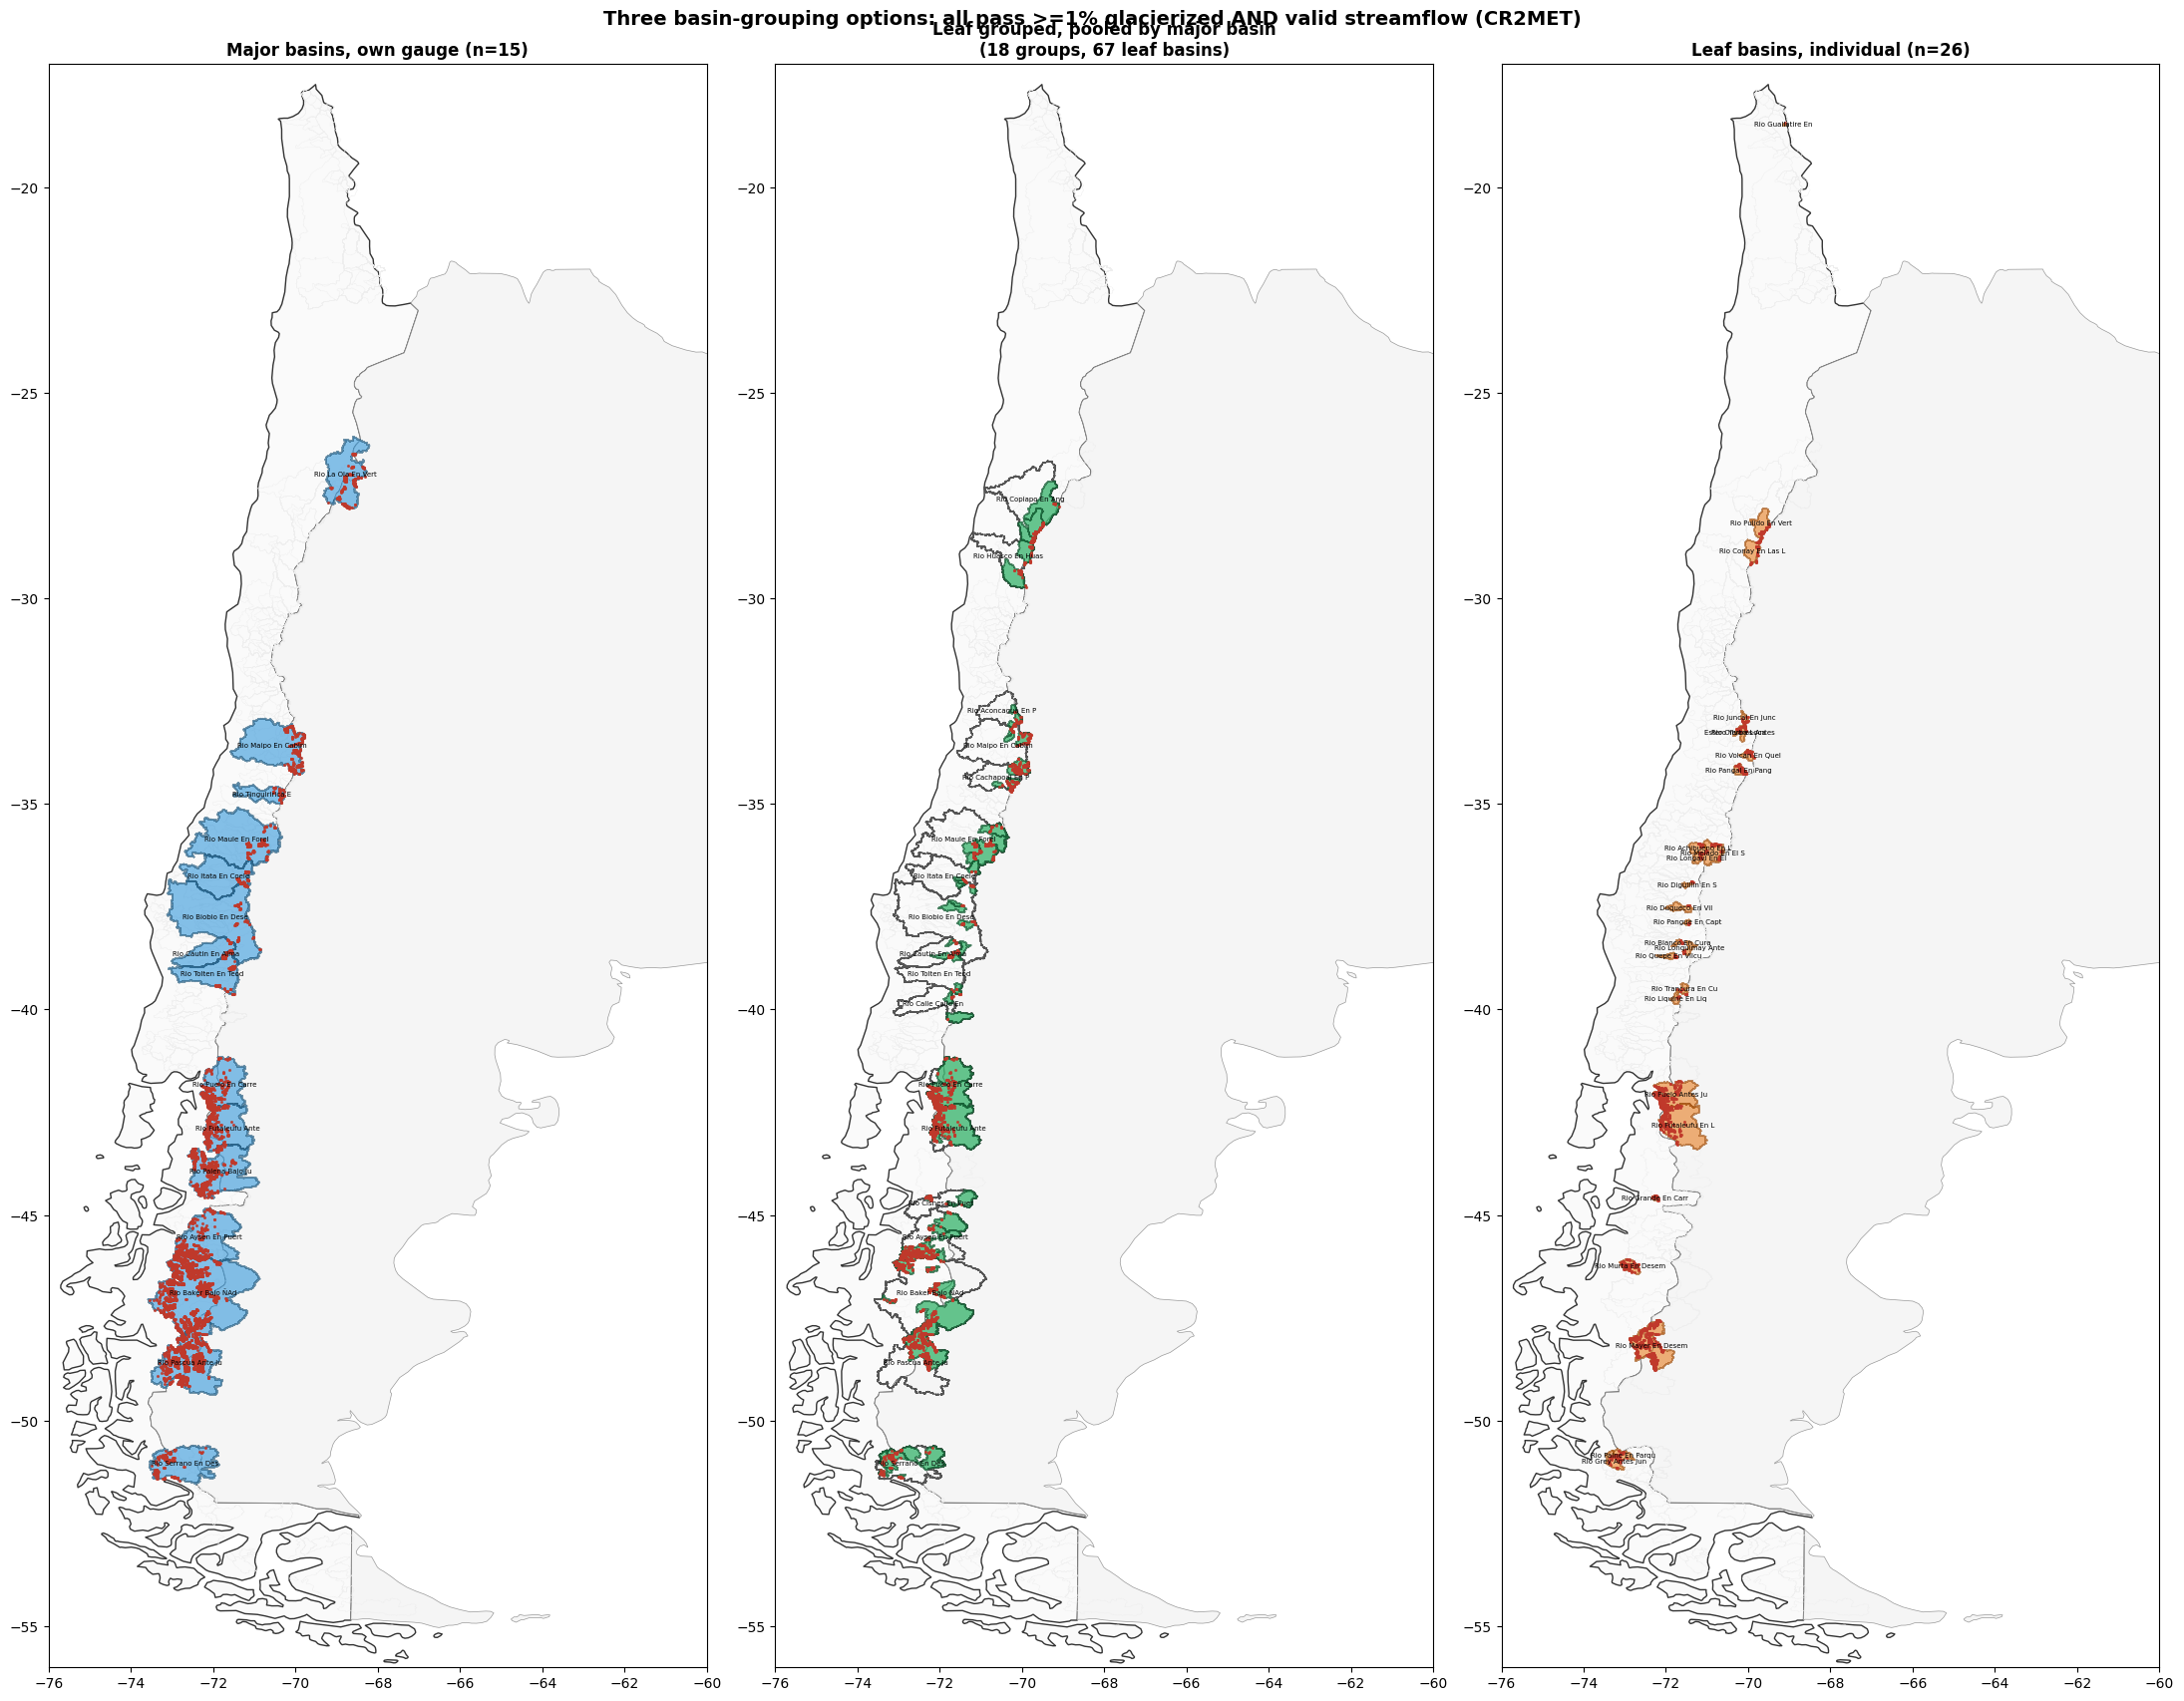

In [ ]:
# ── Major (own gauge) final set ──────────────────────────────────────────────
major_area_pct = {}
for g in df_glacierized_major['gauge_id']:
    total = glacier_area_by_gauge.get(g,0) + sum(glacier_area_by_gauge.get(n,0) for n in contained_map.get(g,[]))
    area = df_glacierized_major.set_index('gauge_id').loc[g,'area_km2']
    major_area_pct[g] = total/area*100

major_final_ids = [g for g in df_glacierized_major['gauge_id']
                    if major_area_pct[g] >= 1.0 and not np.isnan(basin_fraction(g, dataset='CR2MET'))]

# ── Leaf grouped final set: major basins with a valid pooled leaf value ──────
leaf_grouped_final_major_ids = [g for g in df_glacierized_major['gauge_id']
                                 if major_area_pct[g] >= 1.0
                                 and not np.isnan(compute_leaf_fraction_ds(g, leaf_ids_final_clean, dataset='CR2MET'))]
# the actual computation units: the leaf sub-basins nested inside those majors
leaf_grouped_final_leaf_ids = [lid for lid, mid in leaf_to_major.items() if mid in leaf_grouped_final_major_ids]

# ── Leaf individual final set ────────────────────────────────────────────────
leaf_pct_lookup = leaf_area.set_index('gauge_id')['pct'].to_dict()
leaf_final_ids = [g for g in leaf_ids
                  if leaf_pct_lookup.get(g,0) >= 1.0 and not np.isnan(basin_fraction(g, dataset='CR2MET'))]

print(f'Major final: {len(major_final_ids)}')
print(f'Leaf grouped final: {len(leaf_grouped_final_major_ids)} major groups, {len(leaf_grouped_final_leaf_ids)} leaf basins inside them')
print(f'Leaf individual final: {len(leaf_final_ids)}')

# ── Three-panel map ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(22, 17))

# Panel 1: Major, own gauge
ax = axes[0]
if has_borders:
    chile.plot(ax=ax, facecolor='#fafafa', edgecolor='#333333', linewidth=1.0, zorder=0)
    arg.plot(ax=ax, facecolor='#f5f5f5', edgecolor='#999999', linewidth=0.5, zorder=0)
bounds_all.plot(ax=ax, facecolor='none', edgecolor='#eeeeee', linewidth=0.2, zorder=1)
sub = bounds_all[bounds_all['gauge_id'].isin(major_final_ids)]
sub.plot(ax=ax, facecolor='#3498db', alpha=0.6, edgecolor='#1a5276', linewidth=1.0, zorder=2)
glaciers_in = gpd.sjoin(gdf_rgi, sub[['gauge_id','geometry']], how='inner', predicate='within')
ax.scatter(glaciers_in.CenLon, glaciers_in.CenLat, color='#c0392b', s=1.5, zorder=3, alpha=0.8)
for _, row in sub.iterrows():
    c = row.geometry.centroid
    ax.text(c.x, c.y, row['gauge_name'][:18], fontsize=5, ha='center', va='center', zorder=4)
ax.set_title(f'Major basins, own gauge (n={len(major_final_ids)})', fontsize=12, fontweight='bold')
ax.set_xlim(-76, -60); ax.set_ylim(-56, -17); ax.set_aspect('equal')

# Panel 2: Leaf grouped -- major outline dashed (label only), leaf sub-basins filled
ax = axes[1]
if has_borders:
    chile.plot(ax=ax, facecolor='#fafafa', edgecolor='#333333', linewidth=1.0, zorder=0)
    arg.plot(ax=ax, facecolor='#f5f5f5', edgecolor='#999999', linewidth=0.5, zorder=0)
bounds_all.plot(ax=ax, facecolor='none', edgecolor='#eeeeee', linewidth=0.2, zorder=1)
bounds_all[bounds_all['gauge_id'].isin(leaf_grouped_final_major_ids)].plot(
    ax=ax, facecolor='none', edgecolor='#555555', linewidth=1.0, linestyle='--', zorder=2)
sub_leaf = bounds_all[bounds_all['gauge_id'].isin(leaf_grouped_final_leaf_ids)]
sub_leaf.plot(ax=ax, facecolor='#27ae60', alpha=0.7, edgecolor='#145a32', linewidth=0.8, zorder=3)
glaciers_in2 = gpd.sjoin(gdf_rgi, sub_leaf[['gauge_id','geometry']], how='inner', predicate='within')
ax.scatter(glaciers_in2.CenLon, glaciers_in2.CenLat, color='#c0392b', s=1.5, zorder=4, alpha=0.8)
for _, row in bounds_all[bounds_all['gauge_id'].isin(leaf_grouped_final_major_ids)].iterrows():
    c = row.geometry.centroid
    ax.text(c.x, c.y, row['gauge_name'][:18], fontsize=5, ha='center', va='center', zorder=5)
ax.set_title(f'Leaf grouped, pooled by major basin\n({len(leaf_grouped_final_major_ids)} groups, {len(leaf_grouped_final_leaf_ids)} leaf basins)',
             fontsize=12, fontweight='bold')
ax.set_xlim(-76, -60); ax.set_ylim(-56, -17); ax.set_aspect('equal')

# Panel 3: Leaf individual
ax = axes[2]
if has_borders:
    chile.plot(ax=ax, facecolor='#fafafa', edgecolor='#333333', linewidth=1.0, zorder=0)
    arg.plot(ax=ax, facecolor='#f5f5f5', edgecolor='#999999', linewidth=0.5, zorder=0)
bounds_all.plot(ax=ax, facecolor='none', edgecolor='#eeeeee', linewidth=0.2, zorder=1)
sub3 = bounds_all[bounds_all['gauge_id'].isin(leaf_final_ids)]
sub3.plot(ax=ax, facecolor='#e67e22', alpha=0.6, edgecolor='#9c4a08', linewidth=0.8, zorder=2)
glaciers_in3 = gpd.sjoin(gdf_rgi, sub3[['gauge_id','geometry']], how='inner', predicate='within')
ax.scatter(glaciers_in3.CenLon, glaciers_in3.CenLat, color='#c0392b', s=1.5, zorder=3, alpha=0.8)
for _, row in sub3.iterrows():
    c = row.geometry.centroid
    ax.text(c.x, c.y, row['gauge_name'][:18], fontsize=5, ha='center', va='center', zorder=4)
ax.set_title(f'Leaf basins, individual (n={len(leaf_final_ids)})', fontsize=12, fontweight='bold')
ax.set_xlim(-76, -60); ax.set_ylim(-56, -17); ax.set_aspect('equal')

plt.suptitle('Three basin-grouping options: all pass >=1% glacierized AND valid streamflow (CR2MET)',
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/three_grouping_options_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

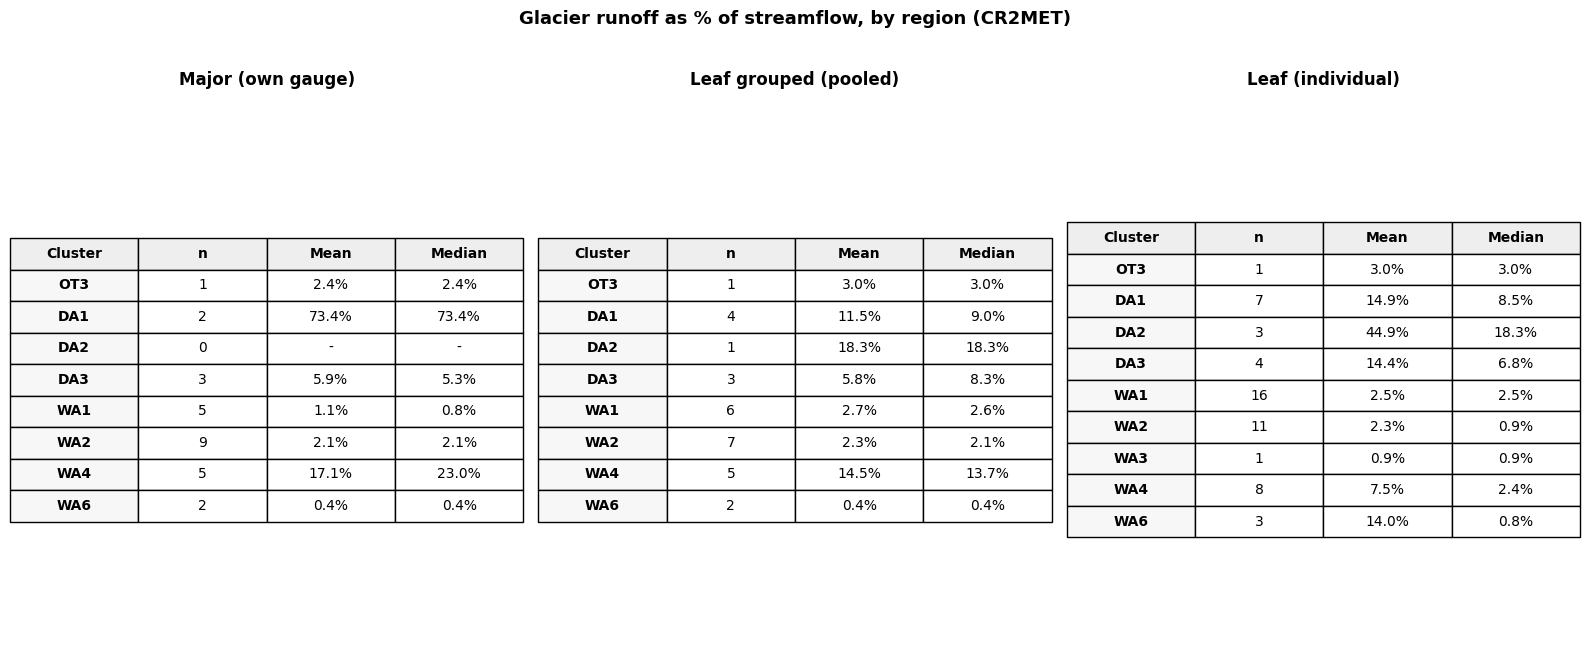

Saved: /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/basin_grouping_by_cluster_table.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 0.5*len(cluster_order) + 1.5))

for ax, df_s, title in zip(
        axes,
        [prep(summary_major, None), prep(summary_grouped, None), prep(summary_leaf, None)],
        ['Major (own gauge)', 'Leaf grouped (pooled)', 'Leaf (individual)']):
    ax.axis('off')
    table_data = make_table_data(df_s)
    tbl = ax.table(cellText=table_data, colLabels=['Cluster','n','Mean','Median'],
                    loc='center', cellLoc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1, 1.7)
    for i in range(4):
        tbl[(0, i)].set_facecolor('#eeeeee')
        tbl[(0, i)].set_text_props(fontweight='bold')
    for r in range(1, len(table_data)+1):
        tbl[(r, 0)].set_facecolor('#f7f7f7')
        tbl[(r, 0)].set_text_props(fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold', pad=12)

plt.suptitle('Glacier runoff as % of streamflow, by region (CR2MET)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/basin_grouping_by_cluster_table.png', dpi=200, bbox_inches='tight')
plt.show()
print(f'Saved: {OUTPUT_ROOT}/basin_grouping_by_cluster_table.png')

In [ ]:
leaf_group_area = bounds_all[bounds_all['gauge_id'].isin(leaf_to_major.keys())].copy()
leaf_group_area['major_id'] = leaf_group_area['gauge_id'].map(leaf_to_major)
# no merge needed -- bounds_all already has area_km2 natively

group_totals = leaf_group_area.groupby('major_id')['area_km2'].agg(
    n_leaves='count', summed_leaf_area='sum').reset_index()
group_totals['avg_single_leaf_area'] = group_totals['summed_leaf_area'] / group_totals['n_leaves']
group_totals['major_name'] = group_totals['major_id'].map(df_glacierized_major.set_index('gauge_id')['gauge_name'])

print(group_totals[['major_name','n_leaves','avg_single_leaf_area','summed_leaf_area']].to_string(index=False))

                           major_name  n_leaves  avg_single_leaf_area  summed_leaf_area
             Rio Caquena En Vertedero         1             49.711859         49.711859
  Rio Calle Calle En Balsa San Javier         2            698.505231       1397.010462
   Rio Lauca En Japu (O En El Limite)         2            212.899670        425.799339
                   Rio Bueno En Bueno         2           1017.200080       2034.400160
          Rio Pilmaiquen En San Pablo         1            503.039490        503.039490
                Rio Rahue En Forrahue         2            657.337860       1314.675719
            Rio Maullin En Las Quemas         1           1624.470028       1624.470028
     Rio Chamiza Ante Junta Rio Chico         1            588.894062        588.894062
         Rio Puelo En Carrera Basilio         2           4189.322559       8378.645119
                Rio Blanco En Chaiten         1             78.700278         78.700278
  Rio Futaleufu Ante Junta Rio M

# check out leaves that are one step up in basin size: 

In [ ]:
# ── Build the intermediate ("one tier downstream") basin for each finest leaf ──
from basin_hierarchy_utils import compute_basin_hierarchy, build_containment_maps, get_immediate_parent
intermediate_by_leaf = {}
for leaf_id in leaf_ids_final_clean:
    parent = get_immediate_parent(leaf_id, container_map, area_by_id)
    intermediate_by_leaf[leaf_id] = parent  # None if leaf has no parent at all

# how many finest leaves actually have a real intermediate gauge (not just jumping straight to major)?
major_ids_set = set(df_glacierized_major['gauge_id'])
has_real_intermediate = {leaf: parent for leaf, parent in intermediate_by_leaf.items()
                          if parent is not None and parent not in major_ids_set}

print(f'Finest leaves with a real intermediate gauge between them and the major basin: '
      f'{len(has_real_intermediate)} of {len(leaf_ids_final_clean)}')
print(f'Finest leaves that jump straight to the major basin (no intermediate exists): '
      f'{sum(1 for p in intermediate_by_leaf.values() if p in major_ids_set)}')

unique_intermediates = set(has_real_intermediate.values())
print(f'Unique intermediate-tier basins: {len(unique_intermediates)}')

Finest leaves with a real intermediate gauge between them and the major basin: 75 of 101
Finest leaves that jump straight to the major basin (no intermediate exists): 16
Unique intermediate-tier basins: 60


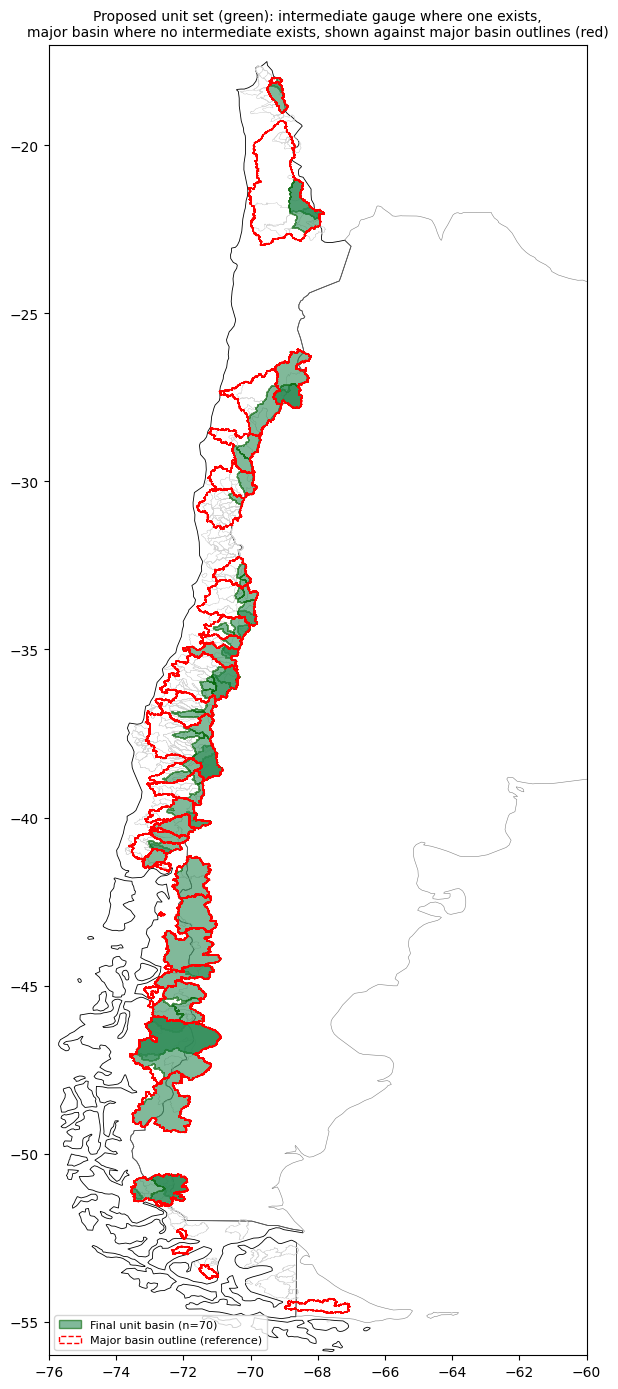

Total units in this final set: 70
  Intermediate basins: 60
  Major basins used as substitute: 10


In [ ]:
# final unit set: intermediate tier where it exists, major basin for the 16 that jump straight to major
unique_intermediate_ids = set(has_real_intermediate.values())          # 60 basins
unique_major_substitute_ids = set(jump_to_major_ids.values())          # majors standing in for the 16 leaves
final_unit_ids = unique_intermediate_ids | unique_major_substitute_ids

fig, ax = plt.subplots(figsize=(9, 14))

chile.boundary.plot(ax=ax, color='black', linewidth=0.6)
if has_borders:
    arg.boundary.plot(ax=ax, color='gray', linewidth=0.4)
bounds_all.boundary.plot(ax=ax, color='lightgray', linewidth=0.3)

# all final units (intermediate + substitute majors) filled the same green
final_rows = bounds_all[bounds_all['gauge_id'].isin(final_unit_ids)]
final_rows.plot(ax=ax, color='seagreen', alpha=0.6, edgecolor='darkgreen', linewidth=0.7, zorder=3)

# major (biggest level) basins shown as red outlines for reference
major_rows = bounds_all[bounds_all['gauge_id'].isin(df_glacierized_major['gauge_id'])]
major_rows.boundary.plot(ax=ax, color='red', linewidth=1.1, linestyle='--', zorder=4)

ax.set_xlim(-76, -60)
ax.set_ylim(-56, -17)
ax.set_aspect('equal')
ax.set_title('Proposed unit set (green): intermediate gauge where one exists,\n'
              'major basin where no intermediate exists, shown against major basin outlines (red)',
              fontsize=10)

legend_elements = [
    Patch(facecolor='seagreen', alpha=0.6, edgecolor='darkgreen',
          label=f'Final unit basin (n={len(final_unit_ids)})'),
    Patch(facecolor='none', edgecolor='red', linestyle='--', label='Major basin outline (reference)')
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=8)

plt.tight_layout()
plt.savefig('final_unit_set_intermediate_plus_major.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Total units in this final set: {len(final_unit_ids)}")
print(f"  Intermediate basins: {len(unique_intermediate_ids)}")
print(f"  Major basins used as substitute: {len(unique_major_substitute_ids)}")

Unique basins at one level up: 59
  Landed directly on a major basin: 17
  Still an intermediate basin (parent of the old intermediate): 42


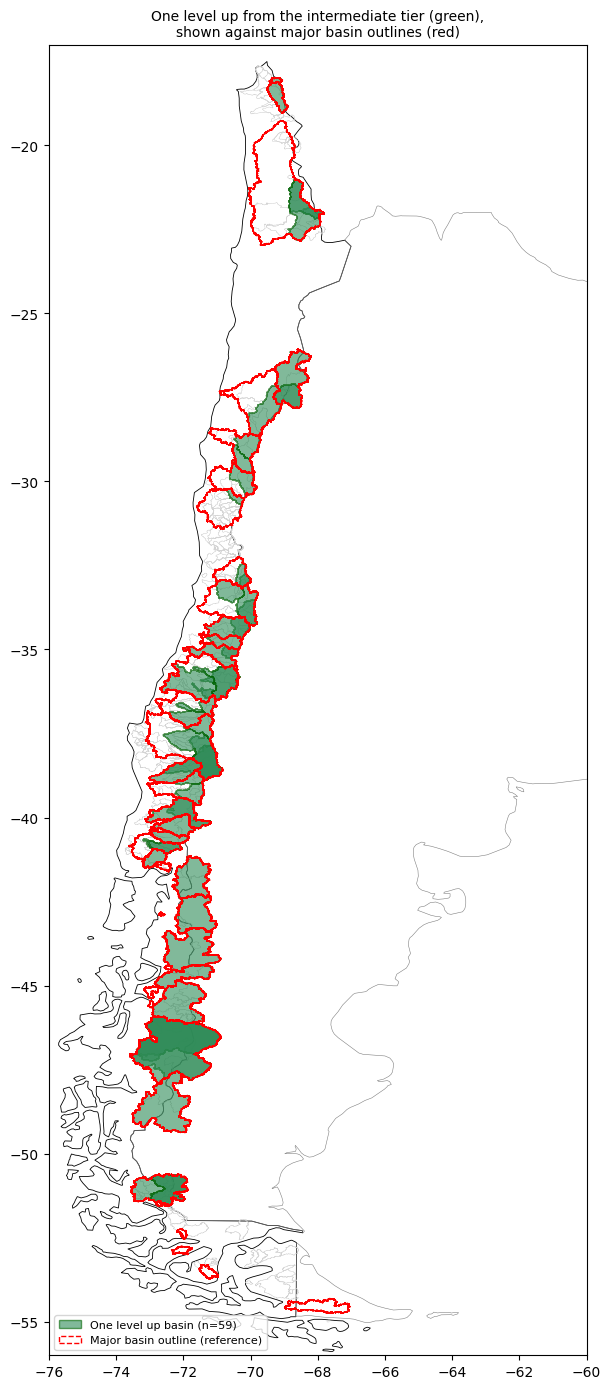

In [ ]:
# one level up: for leaves that had an intermediate, take that intermediate's own parent
# for the 16 that already jump straight to major, there is nowhere higher to go, so they stay at major
next_level_by_leaf = {}

for leaf_id, intermediate_id in has_real_intermediate.items():
    next_parent = get_immediate_parent(intermediate_id, container_map, area_by_id)
    if next_parent is None:
        next_level_by_leaf[leaf_id] = intermediate_id  # no parent found, stay at intermediate
    else:
        next_level_by_leaf[leaf_id] = next_parent

for leaf_id, major_id in jump_to_major_ids.items():
    next_level_by_leaf[leaf_id] = major_id  # already at major, nothing higher available

unique_next_level_ids = set(next_level_by_leaf.values())

# how many of these next-level units landed directly on a major basin vs a new intermediate above the old one
landed_on_major = unique_next_level_ids & major_ids_set
still_intermediate = unique_next_level_ids - major_ids_set

print(f"Unique basins at one level up: {len(unique_next_level_ids)}")
print(f"  Landed directly on a major basin: {len(landed_on_major)}")
print(f"  Still an intermediate basin (parent of the old intermediate): {len(still_intermediate)}")

fig, ax = plt.subplots(figsize=(9, 14))

chile.boundary.plot(ax=ax, color='black', linewidth=0.6)
if has_borders:
    arg.boundary.plot(ax=ax, color='gray', linewidth=0.4)
bounds_all.boundary.plot(ax=ax, color='lightgray', linewidth=0.3)

# all one-level-up units filled green
next_level_rows = bounds_all[bounds_all['gauge_id'].isin(unique_next_level_ids)]
next_level_rows.plot(ax=ax, color='seagreen', alpha=0.6, edgecolor='darkgreen', linewidth=0.7, zorder=3)

# major basins shown as red outlines for reference
major_rows = bounds_all[bounds_all['gauge_id'].isin(df_glacierized_major['gauge_id'])]
major_rows.boundary.plot(ax=ax, color='red', linewidth=1.1, linestyle='--', zorder=4)

ax.set_xlim(-76, -60)
ax.set_ylim(-56, -17)
ax.set_aspect('equal')
ax.set_title('One level up from the intermediate tier (green),\nshown against major basin outlines (red)',
              fontsize=10)

legend_elements = [
    Patch(facecolor='seagreen', alpha=0.6, edgecolor='darkgreen',
          label=f'One level up basin (n={len(unique_next_level_ids)})'),
    Patch(facecolor='none', edgecolor='red', linestyle='--', label='Major basin outline (reference)')
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=8)

plt.tight_layout()
plt.savefig('one_level_up_unit_set.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
def compute_pooled_fraction(leaf_ids, dataset='CR2MET', months=None, years=None):
    leaf_ids = list(leaf_ids)
    if not leaf_ids:
        return np.nan
    glac_frames, q_frames = [], []
    for leaf_id in leaf_ids:
        res = RESULTS[dataset].get(leaf_id)
        if res is None:
            continue
        m = res['monthly'].copy()
        if years is not None:
            m = m[m['year'].isin(years)]
        if months is not None:
            m = m[m['month'].isin(months)]
        m = m.set_index(['year', 'month'])
        glac_frames.append(m[['glacier_runoff_m3']].rename(columns={'glacier_runoff_m3': f'glac_{leaf_id}'}))
        q_frames.append(m[['q_m3_mon']].rename(columns={'q_m3_mon': f'q_{leaf_id}'}))
    if not glac_frames:
        return np.nan
    glac_wide = pd.concat(glac_frames, axis=1)
    q_wide = pd.concat(q_frames, axis=1)
    q_complete_mask = q_wide.notna().all(axis=1) & (q_wide >= 0).all(axis=1)
    q_summed = q_wide[q_complete_mask].sum(axis=1)
    glac_summed = glac_wide[q_complete_mask].sum(axis=1)
    valid = q_summed > 0
    if valid.sum() == 0:
        return np.nan
    return (glac_summed[valid].sum() / q_summed[valid].sum()) * 100

In [ ]:
import inspect
print(inspect.getsource(prep))
print(inspect.getsource(make_table_data))

def prep(df_s, value_col_map=None):
    d = df_s.copy()
    d['cluster'] = pd.Categorical(d['cluster'], categories=cluster_order, ordered=True)
    d = d.sort_values('cluster').reset_index(drop=True)
    return d

def make_table_data(df_s):
    rows = []
    for _, row in df_s.iterrows():
        n = '-' if pd.isna(row['n_valid']) else f'{int(row["n_valid"])}'
        mean = '-' if pd.isna(row['mean']) else f'{row["mean"]:.1f}%'
        median = '-' if pd.isna(row['median']) else f'{row["median"]:.1f}%'
        rows.append([row['cluster'], n, mean, median])
    return rows



Mean glacier fraction (%) by cluster and tier:
tier     Leaflet  Level 1 up  Level 2 up  Major
cluster                                        
OT3          3.0         3.0         3.0    3.0
DA1         14.9        12.4        12.4   11.5
DA2         13.6        13.6        13.6   13.6
DA3          3.5         3.5         4.3    4.3
WA1          2.6         2.6         2.6    2.7
WA2          2.3         2.1         2.0    2.3
WA3          0.9         0.7         NaN    NaN
WA4          7.5        18.3        13.9   11.1
WA5          NaN         NaN         NaN    NaN
WA6         14.0        30.6        30.6    9.8

Median glacier fraction (%) by cluster and tier:
tier     Leaflet  Level 1 up  Level 2 up  Major
cluster                                        
OT3          3.0         3.0         3.0    3.0
DA1          8.5         8.5         8.5    9.0
DA2         13.6        13.6        13.6   13.6
DA3          0.4         0.4         4.3    4.3
WA1          2.6         2.6         2.

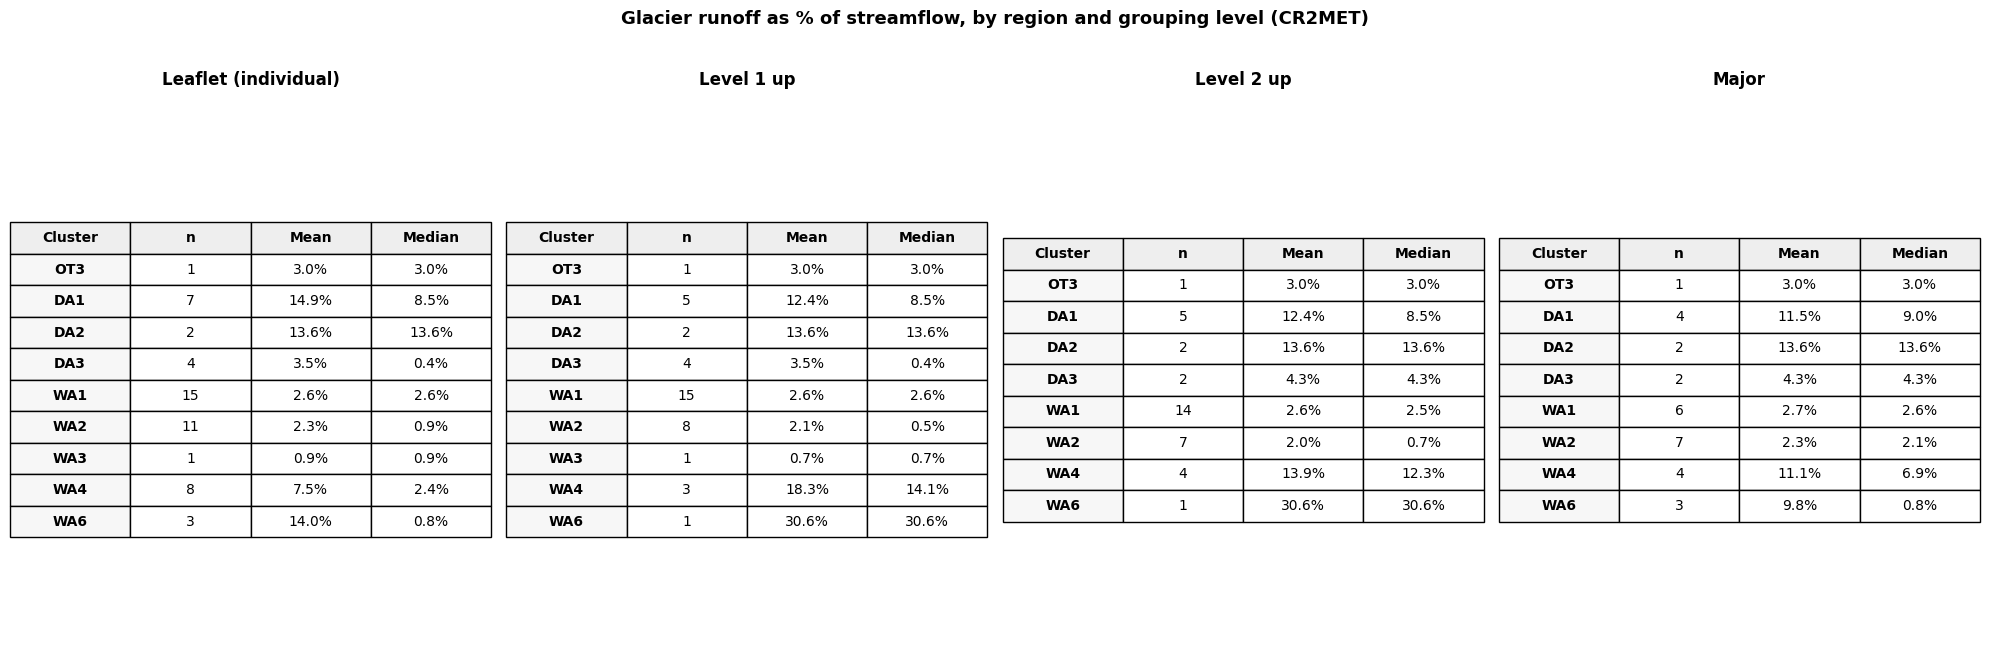

Saved: /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/basin_grouping_by_tier_table.png


In [ ]:
from collections import defaultdict
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

def compute_pooled_fraction(leaf_ids, dataset='CR2MET', months=None, years=None):
    leaf_ids = list(leaf_ids)
    if not leaf_ids:
        return np.nan
    glac_frames, q_frames = [], []
    for leaf_id in leaf_ids:
        res = RESULTS[dataset].get(leaf_id)
        if res is None:
            continue
        m = res['monthly'].copy()
        if years is not None:
            m = m[m['year'].isin(years)]
        if months is not None:
            m = m[m['month'].isin(months)]
        m = m.set_index(['year', 'month'])
        glac_frames.append(m[['glacier_runoff_m3']].rename(columns={'glacier_runoff_m3': f'glac_{leaf_id}'}))
        q_frames.append(m[['q_m3_mon']].rename(columns={'q_m3_mon': f'q_{leaf_id}'}))
    if not glac_frames:
        return np.nan
    glac_wide = pd.concat(glac_frames, axis=1)
    q_wide = pd.concat(q_frames, axis=1)
    q_complete_mask = q_wide.notna().all(axis=1) & (q_wide >= 0).all(axis=1)
    q_summed = q_wide[q_complete_mask].sum(axis=1)
    glac_summed = glac_wide[q_complete_mask].sum(axis=1)
    valid = q_summed > 0
    if valid.sum() == 0:
        return np.nan
    return (glac_summed[valid].sum() / q_summed[valid].sum()) * 100

leaflet_map = {leaf_id: leaf_id for leaf_id in leaf_ids_final_clean}

level1_map = {}
level1_map.update(has_real_intermediate)
level1_map.update(jump_to_major_ids)

level2_map = dict(next_level_by_leaf)

major_map = dict(leaf_to_major)

tier_order = ['Leaflet', 'Level 1 up', 'Level 2 up', 'Major']
tier_maps = {
    'Leaflet': leaflet_map,
    'Level 1 up': level1_map,
    'Level 2 up': level2_map,
    'Major': major_map,
}

rows = []
for tier_name, gmap in tier_maps.items():
    groups = defaultdict(set)
    for leaf_id, grp_id in gmap.items():
        groups[grp_id].add(leaf_id)
    for grp_id, leaves in groups.items():
        frac = compute_pooled_fraction(leaves, dataset='CR2MET')
        grp_name = bounds_all.loc[bounds_all['gauge_id'] == grp_id, 'gauge_name']
        grp_name = grp_name.values[0] if len(grp_name) else str(grp_id)
        rows.append({'tier': tier_name, 'gauge_id': grp_id, 'gauge_name': grp_name,
                      'n_leaves_pooled': len(leaves), 'glacier_pct': frac})

df_tiers = pd.DataFrame(rows)

def assign_dominant_cluster(unit_ids):
    units_gdf = bounds_all[bounds_all['gauge_id'].isin(unit_ids)][['gauge_id', 'geometry']]
    joined = gpd.sjoin(gdf_rgi, units_gdf, how='inner', predicate='within')
    area_by_cluster = joined.groupby(['gauge_id', 'Cluster'])['Area'].sum().reset_index()
    idx = area_by_cluster.groupby('gauge_id')['Area'].idxmax()
    dominant = area_by_cluster.loc[idx, ['gauge_id', 'Cluster']]
    return dict(zip(dominant['gauge_id'], dominant['Cluster']))

cluster_by_unit = assign_dominant_cluster(df_tiers['gauge_id'].unique())
df_tiers['cluster'] = df_tiers['gauge_id'].map(cluster_by_unit)

summary_by_cluster = (
    df_tiers.groupby(['cluster', 'tier'])['glacier_pct']
    .agg(mean='mean', median='median', n_valid='count')
    .reset_index()
)

cluster_order_list = cluster_order if 'cluster_order' in dir() else sorted(df_tiers['cluster'].dropna().unique())

pivot_mean = summary_by_cluster.pivot(index='cluster', columns='tier', values='mean').reindex(cluster_order_list)[tier_order]
pivot_median = summary_by_cluster.pivot(index='cluster', columns='tier', values='median').reindex(cluster_order_list)[tier_order]
pivot_n = summary_by_cluster.pivot(index='cluster', columns='tier', values='n_valid').reindex(cluster_order_list)[tier_order]

print("Mean glacier fraction (%) by cluster and tier:")
print(pivot_mean.round(1).to_string())
print("\nMedian glacier fraction (%) by cluster and tier:")
print(pivot_median.round(1).to_string())
print("\nNumber of units by cluster and tier:")
print(pivot_n.to_string())

overall = df_tiers.groupby('tier')['glacier_pct'].agg(mean='mean', median='median', n_valid='count').reindex(tier_order)
print("\nOverall (all of Chile) by tier:")
print(overall.round(1).to_string())

tier_summary_tables = {}
for tier_name in tier_order:
    df_t = summary_by_cluster[summary_by_cluster['tier'] == tier_name][['cluster', 'n_valid', 'mean', 'median']].copy()
    tier_summary_tables[tier_name] = df_t

summary_leaflet_tbl = tier_summary_tables['Leaflet']
summary_level1_tbl = tier_summary_tables['Level 1 up']
summary_level2_tbl = tier_summary_tables['Level 2 up']
summary_major_tbl = tier_summary_tables['Major']

fig, axes = plt.subplots(1, 4, figsize=(20, 0.5*len(cluster_order_list) + 1.5))

for ax, df_s, title in zip(
        axes,
        [prep(summary_leaflet_tbl, None), prep(summary_level1_tbl, None),
         prep(summary_level2_tbl, None), prep(summary_major_tbl, None)],
        ['Leaflet (individual)', 'Level 1 up', 'Level 2 up', 'Major']):
    ax.axis('off')
    table_data = make_table_data(df_s)
    tbl = ax.table(cellText=table_data, colLabels=['Cluster','n','Mean','Median'],
                    loc='center', cellLoc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1, 1.7)
    for i in range(4):
        tbl[(0, i)].set_facecolor('#eeeeee')
        tbl[(0, i)].set_text_props(fontweight='bold')
    for r in range(1, len(table_data)+1):
        tbl[(r, 0)].set_facecolor('#f7f7f7')
        tbl[(r, 0)].set_text_props(fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold', pad=12)

plt.suptitle('Glacier runoff as % of streamflow, by region and grouping level (CR2MET)',
              fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/basin_grouping_by_tier_table.png', dpi=200, bbox_inches='tight')
plt.show()
print(f'Saved: {OUTPUT_ROOT}/basin_grouping_by_tier_table.png')

In [ ]:
print("WA5 total glacier area (km2):", gdf_rgi[gdf_rgi['Cluster'] == 'WA5']['Area'].sum())
print("WA5 glacier count:", (gdf_rgi['Cluster'] == 'WA5').sum())

WA5 total glacier area (km2): 2588.6939999999995
WA5 glacier count: 711


In [30]:
from collections import defaultdict
import numpy as np
import pandas as pd

def basin_fraction(gid, dataset='CR2MET', months=None):
    res = RESULTS[dataset].get(gid)
    if res is None:
        return np.nan
    m = res['monthly'].copy()
    if months is not None:
        m = m[m['month'].isin(months)]
    m = m[m['q_m3_mon'] > 0].dropna(subset=['glacier_runoff_m3','q_m3_mon'])
    if len(m) == 0:
        return np.nan
    return (m['glacier_runoff_m3'].sum() / m['q_m3_mon'].sum()) * 100

def compare_own_vs_pooled(group_map, dataset='CR2MET'):
    groups = defaultdict(set)
    for leaf_id, grp_id in group_map.items():
        groups[grp_id].add(leaf_id)

    rows = []
    for grp_id, leaves in groups.items():
        has_own_record = grp_id in RESULTS[dataset]
        own_frac = basin_fraction(grp_id, dataset=dataset) if has_own_record else np.nan
        pooled_frac = compute_pooled_fraction(leaves, dataset=dataset)

        own_n_valid = np.nan
        if has_own_record:
            m = RESULTS[dataset][grp_id]['monthly']
            own_n_valid = (m['q_m3_mon'].notna() & (m['q_m3_mon'] >= 0)).sum()

        grp_name = bounds_all.loc[bounds_all['gauge_id'] == grp_id, 'gauge_name']
        grp_name = grp_name.values[0] if len(grp_name) else str(grp_id)

        rows.append({
            'gauge_id': grp_id, 'gauge_name': grp_name, 'n_leaves_pooled': len(leaves),
            'has_own_gauge_record': has_own_record, 'own_n_valid_months': own_n_valid,
            'own_fraction_pct': own_frac, 'pooled_fraction_pct': pooled_frac,
            'diff_own_minus_pooled': own_frac - pooled_frac if has_own_record else np.nan
        })
    return pd.DataFrame(rows)

In [33]:
# intermediate tier: immediate parent of each finest leaf
intermediate_by_leaf = {}
for leaf_id in leaf_ids_final_clean:
    parent = get_immediate_parent(leaf_id, container_map, area_by_id)
    intermediate_by_leaf[leaf_id] = parent

major_ids_set = set(df_glacierized_major['gauge_id'])

has_real_intermediate = {leaf: parent for leaf, parent in intermediate_by_leaf.items()
                          if parent is not None and parent not in major_ids_set}
jump_to_major_ids = {leaf: parent for leaf, parent in intermediate_by_leaf.items()
                      if parent in major_ids_set}

print(f"Finest leaves with a real intermediate gauge: {len(has_real_intermediate)} of {len(leaf_ids_final_clean)}")
print(f"Finest leaves that jump straight to the major basin: {len(jump_to_major_ids)}")

# one level up: the intermediate's own parent, or the major if already there
next_level_by_leaf = {}
for leaf_id, intermediate_id in has_real_intermediate.items():
    next_parent = get_immediate_parent(intermediate_id, container_map, area_by_id)
    if next_parent is None:
        next_level_by_leaf[leaf_id] = intermediate_id
    else:
        next_level_by_leaf[leaf_id] = next_parent

for leaf_id, major_id in jump_to_major_ids.items():
    next_level_by_leaf[leaf_id] = major_id

print(f"Unique basins at one level up: {len(set(next_level_by_leaf.values()))}")

NameError: name 'get_immediate_parent' is not defined

In [31]:
def check_gauge_quality(gauge_ids, dataset='CR2MET'):
    rows = []
    for gid in set(gauge_ids):
        res = RESULTS[dataset].get(gid)
        if res is None:
            continue
        m = res['monthly'].copy()
        m = m[m['q_m3_mon'] > 0].dropna(subset=['glacier_runoff_m3', 'q_m3_mon'])
        if len(m) == 0:
            continue
        n_bad = (m['glacier_runoff_m3'] > m['q_m3_mon']).sum()
        n_valid = len(m)
        name_row = bounds_all.loc[bounds_all['gauge_id'] == gid, 'gauge_name']
        name = name_row.values[0] if len(name_row) else gid
        rows.append({'gauge_id': gid, 'gauge_name': name, 'n_valid_months': n_valid,
                      'n_bad_months': n_bad, 'pct_bad': n_bad / n_valid * 100})
    return pd.DataFrame(rows).sort_values('pct_bad', ascending=False).reset_index(drop=True)

# leaflet tier: every leaf's own record is used directly, so check all of them
df_quality_leaflet = check_gauge_quality(leaf_ids_final_clean)

# level 1 and level 2 own-gauge records (only the ones that actually have a record)
level1_own_ids = [gid for gid in set(level1_map.values()) if gid in RESULTS['CR2MET']]
level2_own_ids = [gid for gid in set(level2_map.values()) if gid in RESULTS['CR2MET']]
df_quality_level1 = check_gauge_quality(level1_own_ids)
df_quality_level2 = check_gauge_quality(level2_own_ids)

# major own-gauge records
major_own_ids = [gid for gid in set(major_map.values()) if gid in RESULTS['CR2MET']]
df_quality_major = check_gauge_quality(major_own_ids)

for name, df_q in [('Leaflet', df_quality_leaflet), ('Level 1 own', df_quality_level1),
                    ('Level 2 own', df_quality_level2), ('Major own', df_quality_major)]:
    n_any_bad = (df_q['n_bad_months'] > 0).sum()
    n_over_10pct = (df_q['pct_bad'] > 10).sum()
    n_over_25pct = (df_q['pct_bad'] > 25).sum()
    print(f"{name}: {len(df_q)} gauges checked, {n_any_bad} with at least 1 bad month, "
          f"{n_over_10pct} over 10% bad months, {n_over_25pct} over 25% bad months")

print("\nWorst offenders across all tiers combined:")
df_all_quality = pd.concat([
    df_quality_leaflet.assign(tier='Leaflet'),
    df_quality_level1.assign(tier='Level 1 own'),
    df_quality_level2.assign(tier='Level 2 own'),
    df_quality_major.assign(tier='Major own'),
])
print(df_all_quality.sort_values('pct_bad', ascending=False).head(20).to_string(index=False))

NameError: name 'level1_map' is not defined

In [23]:
def check_gauge_quality_v2(gauge_ids, dataset='CR2MET'):
    rows = []
    for gid in set(gauge_ids):
        res = RESULTS[dataset].get(gid)
        if res is None:
            continue
        m = res['monthly'].copy()
        m = m[m['q_m3_mon'] > 0].dropna(subset=['glacier_runoff_m3', 'q_m3_mon'])
        if len(m) == 0:
            continue
        m['ratio'] = m['glacier_runoff_m3'] / m['q_m3_mon']
        bad = m[m['ratio'] > 1]
        n_valid = len(m)
        n_bad = len(bad)
        name_row = bounds_all.loc[bounds_all['gauge_id'] == gid, 'gauge_name']
        name = name_row.values[0] if len(name_row) else gid
        rows.append({
            'gauge_id': gid, 'gauge_name': name, 'n_valid_months': n_valid, 'n_bad_months': n_bad,
            'pct_bad': n_bad / n_valid * 100,
            'mean_bad_ratio': bad['ratio'].mean() if n_bad > 0 else np.nan,
            'max_bad_ratio': bad['ratio'].max() if n_bad > 0 else np.nan,
        })
    return pd.DataFrame(rows).sort_values('pct_bad', ascending=False).reset_index(drop=True)

df_quality_leaflet_v2 = check_gauge_quality_v2(leaf_ids_final_clean)
df_quality_level1_v2 = check_gauge_quality_v2(level1_own_ids)
df_quality_level2_v2 = check_gauge_quality_v2(level2_own_ids)
df_quality_major_v2 = check_gauge_quality_v2(major_own_ids)

df_all_quality_v2 = pd.concat([
    df_quality_leaflet_v2.assign(tier='Leaflet'),
    df_quality_level1_v2.assign(tier='Level 1 own'),
    df_quality_level2_v2.assign(tier='Level 2 own'),
    df_quality_major_v2.assign(tier='Major own'),
])

print("Gauges with at least 1 bad month, sorted by pct_bad:")
print(df_all_quality_v2[df_all_quality_v2['n_bad_months'] > 0]
      .sort_values('pct_bad', ascending=False)
      .to_string(index=False))

NameError: name 'level1_own_ids' is not defined

In [24]:
protected_gauge_ids = {'8141001', '9140001', '11701001', '8132001', '6006001', '11505001', '12287001'}

def classify_gauge(row, pct_threshold=10, magnitude_threshold=5):
    if row['gauge_id'] in protected_gauge_ids:
        return 'keep_as_is'
    if row['n_bad_months'] == 0:
        return 'clean'
    if row['pct_bad'] > pct_threshold:
        return 'exclude_systematic'
    if row['max_bad_ratio'] > magnitude_threshold:
        return 'mask_bad_months_only'
    return 'keep_as_is'

df_all_quality_v2['classification'] = df_all_quality_v2.apply(classify_gauge, axis=1)
print(df_all_quality_v2.drop_duplicates('gauge_id')[['gauge_id','gauge_name','pct_bad','max_bad_ratio','classification']]
      .sort_values('classification').to_string(index=False))

NameError: name 'df_all_quality_v2' is not defined

In [25]:
# 1) gauges to exclude entirely (systematically bad, >10% of months impossible)
exclude_gauge_ids = {
    '6035001', '3806001', '7306001', '7317003', '3421001', '3414001',
    '3430001', '3430003', '1020003', '3022001', '7321002', '6008005', '5403002'
}

# 2) clean versions of the core functions: every month where glacier runoff exceeds Q gets dropped,
#    regardless of which gauge it is, on top of the existing missing/non-positive Q filter
def basin_fraction_clean(gid, dataset='CR2MET', months=None):
    res = RESULTS[dataset].get(gid)
    if res is None:
        return np.nan
    m = res['monthly'].copy()
    if months is not None:
        m = m[m['month'].isin(months)]
    m = m[m['q_m3_mon'] > 0].dropna(subset=['glacier_runoff_m3', 'q_m3_mon'])
    m = m[m['glacier_runoff_m3'] <= m['q_m3_mon']]  # drop physically impossible months
    if len(m) == 0:
        return np.nan
    return (m['glacier_runoff_m3'].sum() / m['q_m3_mon'].sum()) * 100

def compute_pooled_fraction_clean(leaf_ids, dataset='CR2MET', months=None, years=None):
    leaf_ids = [lid for lid in leaf_ids if lid not in exclude_gauge_ids]
    if not leaf_ids:
        return np.nan
    glac_frames, q_frames = [], []
    for leaf_id in leaf_ids:
        res = RESULTS[dataset].get(leaf_id)
        if res is None:
            continue
        m = res['monthly'].copy()
        if years is not None:
            m = m[m['year'].isin(years)]
        if months is not None:
            m = m[m['month'].isin(months)]
        m = m.set_index(['year', 'month'])
        bad_mask = m['glacier_runoff_m3'] > m['q_m3_mon']
        m.loc[bad_mask, ['glacier_runoff_m3', 'q_m3_mon']] = np.nan  # drop impossible months only
        glac_frames.append(m[['glacier_runoff_m3']].rename(columns={'glacier_runoff_m3': f'glac_{leaf_id}'}))
        q_frames.append(m[['q_m3_mon']].rename(columns={'q_m3_mon': f'q_{leaf_id}'}))
    if not glac_frames:
        return np.nan
    glac_wide = pd.concat(glac_frames, axis=1)
    q_wide = pd.concat(q_frames, axis=1)
    q_complete_mask = q_wide.notna().all(axis=1) & (q_wide >= 0).all(axis=1)
    q_summed = q_wide[q_complete_mask].sum(axis=1)
    glac_summed = glac_wide[q_complete_mask].sum(axis=1)
    valid = q_summed > 0
    if valid.sum() == 0:
        return np.nan
    return (glac_summed[valid].sum() / q_summed[valid].sum()) * 100

# 3) rebuild leaf set and tier maps excluding the systematically bad gauges
leaf_ids_final_clean_v2 = [lid for lid in leaf_ids_final_clean if lid not in exclude_gauge_ids]

leaflet_map_clean = {leaf_id: leaf_id for leaf_id in leaf_ids_final_clean_v2}
level1_map_clean = {k: v for k, v in level1_map.items() if k in leaf_ids_final_clean_v2}
level2_map_clean = {k: v for k, v in level2_map.items() if k in leaf_ids_final_clean_v2}
major_map_clean = {k: v for k, v in major_map.items() if k in leaf_ids_final_clean_v2}

tier_maps_clean = {
    'Leaflet': leaflet_map_clean,
    'Level 1 up': level1_map_clean,
    'Level 2 up': level2_map_clean,
    'Major': major_map_clean,
}

# 4) rebuild df_tiers using the cleaned functions
rows = []
for tier_name, gmap in tier_maps_clean.items():
    groups = defaultdict(set)
    for leaf_id, grp_id in gmap.items():
        groups[grp_id].add(leaf_id)
    for grp_id, leaves in groups.items():
        frac = compute_pooled_fraction_clean(leaves, dataset='CR2MET')
        grp_name = bounds_all.loc[bounds_all['gauge_id'] == grp_id, 'gauge_name']
        grp_name = grp_name.values[0] if len(grp_name) else str(grp_id)
        rows.append({'tier': tier_name, 'gauge_id': grp_id, 'gauge_name': grp_name,
                      'n_leaves_pooled': len(leaves), 'glacier_pct': frac})

df_tiers_clean = pd.DataFrame(rows)

overall_clean = (df_tiers_clean.groupby('tier')['glacier_pct']
                  .agg(mean='mean', median='median', n_valid='count')
                  .reindex(tier_order))

print("Overall (all of Chile) by tier, after excluding bad gauges and masking bad months:")
print(overall_clean.round(1).to_string())

print("\nFor comparison, the uncleaned version:")
print(overall.round(1).to_string())

NameError: name 'level1_map' is not defined

In [26]:
# assign dominant cluster to each cleaned unit (same method as before, glacier area weighted)
cluster_by_unit_clean = assign_dominant_cluster(df_tiers_clean['gauge_id'].unique())
df_tiers_clean['cluster'] = df_tiers_clean['gauge_id'].map(cluster_by_unit_clean)

summary_by_cluster_clean = (
    df_tiers_clean.groupby(['cluster', 'tier'])['glacier_pct']
    .agg(mean='mean', median='median', n_valid='count')
    .reset_index()
)

cluster_order_list_clean = cluster_order if 'cluster_order' in dir() else sorted(df_tiers_clean['cluster'].dropna().unique())

pivot_mean_clean = summary_by_cluster_clean.pivot(index='cluster', columns='tier', values='mean').reindex(cluster_order_list_clean)[tier_order]
pivot_median_clean = summary_by_cluster_clean.pivot(index='cluster', columns='tier', values='median').reindex(cluster_order_list_clean)[tier_order]
pivot_n_clean = summary_by_cluster_clean.pivot(index='cluster', columns='tier', values='n_valid').reindex(cluster_order_list_clean)[tier_order]

print("Mean glacier fraction (%) by cluster and tier, after cleaning:")
print(pivot_mean_clean.round(1).to_string())
print("\nMedian glacier fraction (%) by cluster and tier, after cleaning:")
print(pivot_median_clean.round(1).to_string())
print("\nNumber of units by cluster and tier, after cleaning:")
print(pivot_n_clean.to_string())

print("\nFor comparison, mean before cleaning:")
print(pivot_mean.round(1).to_string())

NameError: name 'assign_dominant_cluster' is not defined

In [27]:
megadrought_years = list(range(2010, 2020))  # placeholder, adjust to your actual definition
jfm_months = [1, 2, 3]  # January, February, March, southern hemisphere summer

def build_level1_fraction_table(years=None, months=None, dataset='CR2MET'):
    groups = defaultdict(set)
    for leaf_id, grp_id in level1_map_clean.items():
        groups[grp_id].add(leaf_id)
    rows = []
    for grp_id, leaves in groups.items():
        frac = compute_pooled_fraction_clean(leaves, dataset=dataset, months=months, years=years)
        grp_name = bounds_all.loc[bounds_all['gauge_id'] == grp_id, 'gauge_name']
        grp_name = grp_name.values[0] if len(grp_name) else str(grp_id)
        rows.append({'gauge_id': grp_id, 'gauge_name': grp_name, 'n_leaves_pooled': len(leaves), 'glacier_pct': frac})
    return pd.DataFrame(rows)

df_level1_all_years = build_level1_fraction_table()
df_level1_megadrought = build_level1_fraction_table(years=megadrought_years)
df_level1_jfm = build_level1_fraction_table(months=jfm_months)

summary_windows = pd.DataFrame({
    'All years': [df_level1_all_years['glacier_pct'].mean(), df_level1_all_years['glacier_pct'].median(), df_level1_all_years['glacier_pct'].notna().sum()],
    'Megadrought': [df_level1_megadrought['glacier_pct'].mean(), df_level1_megadrought['glacier_pct'].median(), df_level1_megadrought['glacier_pct'].notna().sum()],
    'JFM only': [df_level1_jfm['glacier_pct'].mean(), df_level1_jfm['glacier_pct'].median(), df_level1_jfm['glacier_pct'].notna().sum()],
}, index=['mean', 'median', 'n_valid'])

print("Level 1 (cleaned), glacier fraction of streamflow by analysis window:")
print(summary_windows.round(1).to_string())

NameError: name 'defaultdict' is not defined

In [28]:
megadrought_years = list(range(2010, 2020))  # 2010-2019

df_level1_all_years = build_level1_fraction_table()
df_level1_megadrought = build_level1_fraction_table(years=megadrought_years)
df_level1_jfm = build_level1_fraction_table(months=jfm_months)

# attach cluster to each, reusing the same dominant-cluster assignment as before
for df_w in [df_level1_all_years, df_level1_megadrought, df_level1_jfm]:
    df_w['cluster'] = df_w['gauge_id'].map(cluster_by_unit_clean)

def cluster_summary(df_w):
    return (df_w.groupby('cluster')['glacier_pct']
            .agg(mean='mean', median='median', n_valid='count')
            .reindex(cluster_order_list_clean))

summary_all = cluster_summary(df_level1_all_years)
summary_mega = cluster_summary(df_level1_megadrought)
summary_jfm = cluster_summary(df_level1_jfm)

combined_windows_by_cluster = pd.DataFrame({
    'All years mean': summary_all['mean'],
    'Megadrought mean': summary_mega['mean'],
    'JFM mean': summary_jfm['mean'],
    'All years median': summary_all['median'],
    'Megadrought median': summary_mega['median'],
    'JFM median': summary_jfm['median'],
    'n_valid': summary_all['n_valid'],
})

print("Level 1 (cleaned), glacier fraction of streamflow by cluster and analysis window:")
print(combined_windows_by_cluster.round(1).to_string())

NameError: name 'defaultdict' is not defined

In [ ]:
level1_unit_ids = sorted(set(level1_map_clean.values()))
level1_geoms = bounds_all[bounds_all['gauge_id'].isin(level1_unit_ids)][['gauge_id', 'gauge_name', 'geometry']].copy()
level1_geoms_utm = level1_geoms.to_crs(epsg=32719)
level1_geoms_utm['area_km2'] = level1_geoms_utm.geometry.area / 1e6

overlap_rows = []
ids = level1_geoms_utm['gauge_id'].tolist()
geoms = level1_geoms_utm.set_index('gauge_id')['geometry']
areas = level1_geoms_utm.set_index('gauge_id')['area_km2']

for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        gid_a, gid_b = ids[i], ids[j]
        geom_a, geom_b = geoms[gid_a], geoms[gid_b]
        if not geom_a.intersects(geom_b):
            continue
        inter_area = geom_a.intersection(geom_b).area / 1e6
        if inter_area < 0.01:  # ignore negligible sliver overlaps from digitization noise
            continue
        pct_of_a = inter_area / areas[gid_a] * 100
        pct_of_b = inter_area / areas[gid_b] * 100
        overlap_rows.append({
            'gauge_id_a': gid_a, 'name_a': bounds_all.loc[bounds_all['gauge_id']==gid_a,'gauge_name'].values[0],
            'gauge_id_b': gid_b, 'name_b': bounds_all.loc[bounds_all['gauge_id']==gid_b,'gauge_name'].values[0],
            'overlap_km2': inter_area, 'pct_of_a': pct_of_a, 'pct_of_b': pct_of_b,
        })

df_overlaps = pd.DataFrame(overlap_rows).sort_values('overlap_km2', ascending=False)
print(f"Level 1 unit pairs with real spatial overlap: {len(df_overlaps)} out of {len(ids)*(len(ids)-1)//2} possible pairs")
print(df_overlaps.to_string(index=False))

Level 1 unit pairs with real spatial overlap: 50 out of 2415 possible pairs
gauge_id_a                                           name_a gauge_id_b                                     name_b  overlap_km2   pct_of_a   pct_of_b
  11536004                 Rio Baker En Angostura Chacabuco   11542001                       Rio Baker En Colonia 16792.931257  99.959380  64.034947
  11530000               Rio Baker En Desague Lago Bertrand   11536004           Rio Baker En Angostura Chacabuco 16002.680435 100.000000  95.255438
  11530000               Rio Baker En Desague Lago Bertrand   11542001                       Rio Baker En Colonia 15995.997249  99.958237  60.996072
   2104013              Rio Loa En Vado Santa Barbara (Doh)    2110031                       Rio Loa En Angostura  5331.731050  99.963853  58.500846
  12289001                     Rio Serrano En Desembocadura   12289002       Rio Serrano En Desague Lago Del Toro  5287.767962  61.605625 100.000000
   8312000                 Rio

In [ ]:
import networkx as nx

# build a graph where an edge means "A is nearly entirely contained within B" (pct_of_a > 90)
G = nx.DiGraph()
G.add_nodes_from(level1_unit_ids)
for _, row in df_overlaps.iterrows():
    if row['pct_of_a'] > 90 and row['pct_of_a'] > row['pct_of_b']:
        G.add_edge(row['gauge_id_a'], row['gauge_id_b'])  # a is nested inside b
    elif row['pct_of_b'] > 90 and row['pct_of_b'] > row['pct_of_a']:
        G.add_edge(row['gauge_id_b'], row['gauge_id_a'])  # b is nested inside a

# for each connected chain, keep only the terminal (most downstream, not nested inside anything else)
chain_terminal_ids = set()
redundant_ids = set()
for component in nx.weakly_connected_components(G):
    sub = G.subgraph(component)
    terminals = [n for n in sub.nodes if sub.out_degree(n) == 0]
    for t in terminals:
        chain_terminal_ids.add(t)
    for n in sub.nodes:
        if n not in terminals:
            redundant_ids.add(n)

print(f"Level 1 units that are nested inside another and should be dropped from national/regional totals: {len(redundant_ids)}")
print(bounds_all[bounds_all['gauge_id'].isin(redundant_ids)][['gauge_id','gauge_name']].to_string(index=False))
print(f"\nLevel 1 units to keep for aggregate statistics (chain terminals plus everything with no nesting at all): "
      f"{len(level1_unit_ids) - len(redundant_ids)}")

Level 1 units that are nested inside another and should be dropped from national/regional totals: 22
gauge_id                                       gauge_name
 1020003                    Rio Lauca En Estancia El Lago
 2103002       Rio San Pedro En Parshall N"2 (Bt. Chilex)
 2104013              Rio Loa En Vado Santa Barbara (Doh)
 3041003       Rio Valle Ancho Antes  Junta Barros Negros
 3041004                    Rio Valle Ancho En La Barrera
 5701002                         Rio Maipo En Las Melosas
 6003001 Rio Cachapoal 5 Km. Aguas Abajo Junta Cortaderal
 7102001                           Rio Teno En Los QueÑEs
 7104002              Rio Teno Despues De Junta Con Claro
 7308002 Rio Maule Bajo Boca Toma Maule Central Pehuenche
 7317003                      Rio Melado En Zona De Presa
 8307002                          Rio Bio-Bio En Llanquen
 8312000                 Rio Bio Bio En Angostura Ralco 1
10100002                Rio Fui En Desage Lago Pirihueico
10343002               Rio Co

In [ ]:
# non-redundant Level 1 units only, per the overlap/nesting fix
level1_units_for_aggregation = [u for u in level1_unit_ids if u not in redundant_ids]
print(f"Level 1 units used for national/regional aggregates: {len(level1_units_for_aggregation)} of {len(level1_unit_ids)}")

# national summary, corrected
df_level1_agg = df_tiers_clean[(df_tiers_clean['tier'] == 'Level 1 up') &
                                (df_tiers_clean['gauge_id'].isin(level1_units_for_aggregation))]

national_corrected = df_level1_agg['glacier_pct'].agg(['mean', 'median', 'count'])
print("\nLevel 1, national, non-redundant units only:")
print(national_corrected.round(1).to_string())

print("\nFor comparison, all 70 units including nested duplicates:")
print(df_tiers_clean[df_tiers_clean['tier'] == 'Level 1 up']['glacier_pct'].agg(['mean', 'median', 'count']).round(1).to_string())

# cluster-level summary, corrected
cluster_summary_corrected = (df_level1_agg.groupby('cluster')['glacier_pct']
                              .agg(mean='mean', median='median', n_valid='count')
                              .reindex(cluster_order_list_clean))

print("\nLevel 1 by cluster, non-redundant units only:")
print(cluster_summary_corrected.round(1).to_string())

print("\nFor comparison, all 70 units including nested duplicates:")
cluster_summary_uncorrected = (df_tiers_clean[df_tiers_clean['tier'] == 'Level 1 up'].groupby('cluster')['glacier_pct']
                                .agg(mean='mean', median='median', n_valid='count')
                                .reindex(cluster_order_list_clean))
print(cluster_summary_uncorrected.round(1).to_string())

Level 1 units used for national/regional aggregates: 48 of 70

Level 1, national, non-redundant units only:
mean       6.4
median     3.4
count     30.0

For comparison, all 70 units including nested duplicates:
mean       5.5
median     3.0
count     39.0

Level 1 by cluster, non-redundant units only:
         mean  median  n_valid
cluster                       
OT3       3.0     3.0      1.0
DA1       7.5     5.9      4.0
DA2      13.6    13.6      2.0
DA3       4.4     0.3      3.0
WA1       2.7     2.6     11.0
WA2       2.8     1.9      6.0
WA3       NaN     NaN      NaN
WA4      20.2    20.2      2.0
WA5       NaN     NaN      NaN
WA6      30.5    30.5      1.0

For comparison, all 70 units including nested duplicates:
         mean  median  n_valid
cluster                       
OT3       3.0     3.0      1.0
DA1       6.6     4.2      5.0
DA2      13.6    13.6      2.0
DA3       3.5     0.4      4.0
WA1       2.5     2.5     14.0
WA2       2.1     0.5      8.0
WA3       0.7    

In [ ]:
# for each excluded gauge, find its own next basin downstream (its immediate parent, same function used for leaves)
next_downstream_for_excluded = {}
for gid in exclude_gauge_ids:
    parent = get_immediate_parent(gid, container_map, area_by_id)
    next_downstream_for_excluded[gid] = parent

# glacier area for the excluded basins themselves, to check Ale's "muy baja superficie glaciar" claim directly
excluded_geoms = bounds_all[bounds_all['gauge_id'].isin(exclude_gauge_ids)][['gauge_id', 'gauge_name', 'geometry']].copy()
excluded_utm = excluded_geoms.to_crs(epsg=32719)
excluded_utm['basin_area_km2'] = excluded_utm.geometry.area / 1e6

joined_excl = gpd.sjoin(gdf_rgi, excluded_geoms[['gauge_id', 'geometry']], how='inner', predicate='within')
glacier_area_by_excluded = joined_excl.groupby('gauge_id')['Area'].sum()

rows = []
for gid in exclude_gauge_ids:
    name = bounds_all.loc[bounds_all['gauge_id'] == gid, 'gauge_name'].values[0]
    own_glacier_km2 = glacier_area_by_excluded.get(gid, 0.0)
    own_basin_km2 = excluded_utm.loc[excluded_utm['gauge_id'] == gid, 'basin_area_km2'].values[0]
    own_glacier_pct_area = own_glacier_km2 / own_basin_km2 * 100 if own_basin_km2 > 0 else np.nan

    downstream_id = next_downstream_for_excluded.get(gid)
    if downstream_id is None:
        rows.append({'excluded_id': gid, 'excluded_name': name, 'own_glacier_km2': own_glacier_km2,
                      'own_basin_km2': own_basin_km2, 'own_glacier_pct_area': own_glacier_pct_area,
                      'downstream_id': None, 'downstream_name': 'NO PARENT FOUND', 'downstream_status': 'n/a',
                      'downstream_glacier_pct': np.nan, 'downstream_n_valid_months': np.nan})
        continue

    downstream_name = bounds_all.loc[bounds_all['gauge_id'] == downstream_id, 'gauge_name']
    downstream_name = downstream_name.values[0] if len(downstream_name) else downstream_id

    if downstream_id in exclude_gauge_ids:
        status = 'ALSO BAD - excluded'
    elif downstream_id in {'7317005', '3404001', '11711000', '11545000'}:
        status = 'mask specific months'
    elif downstream_id in RESULTS['CR2MET']:
        status = 'clean, has own record'
    else:
        status = 'no own gauge record'

    downstream_frac = basin_fraction_clean(downstream_id, dataset='CR2MET') if downstream_id in RESULTS['CR2MET'] else np.nan
    downstream_n_valid = np.nan
    if downstream_id in RESULTS['CR2MET']:
        m = RESULTS['CR2MET'][downstream_id]['monthly']
        downstream_n_valid = (m['q_m3_mon'] > 0).sum()

    rows.append({'excluded_id': gid, 'excluded_name': name, 'own_glacier_km2': own_glacier_km2,
                  'own_basin_km2': own_basin_km2, 'own_glacier_pct_area': own_glacier_pct_area,
                  'downstream_id': downstream_id, 'downstream_name': downstream_name, 'downstream_status': status,
                  'downstream_glacier_pct': downstream_frac, 'downstream_n_valid_months': downstream_n_valid})

df_downstream_check = pd.DataFrame(rows)
print(df_downstream_check.to_string(index=False))

excluded_id                               excluded_name  own_glacier_km2  own_basin_km2  own_glacier_pct_area downstream_id                                  downstream_name     downstream_status  downstream_glacier_pct  downstream_n_valid_months
    3421001                    Rio Manflas En Vertedero            7.605     981.573250              0.774777       3430003                          Rio Copiapo En Pastillo   ALSO BAD - excluded               11.485463                      226.0
    3414001                     Rio Pulido En Vertedero           23.689    2021.798180              1.171680       3430003                          Rio Copiapo En Pastillo   ALSO BAD - excluded               11.485463                      226.0
    3806001         Rio Transito Antes Junta Rio Carmen           22.278    4103.291801              0.542930       3820001                          Rio Huasco En Algodones clean, has own record                7.532215                      218.0
    7317003     

In [ ]:
def walk_downstream(start_id, max_hops=5):
    chain = []
    current_id = start_id
    for hop in range(1, max_hops + 1):
        parent_id = get_immediate_parent(current_id, container_map, area_by_id)
        if parent_id is None:
            chain.append({'hop': hop, 'gauge_id': None, 'gauge_name': 'NO PARENT FOUND (dead end)', 'status': 'dead_end'})
            break
        name = bounds_all.loc[bounds_all['gauge_id'] == parent_id, 'gauge_name']
        name = name.values[0] if len(name) else parent_id

        if parent_id in exclude_gauge_ids:
            status = 'also_bad'
        elif parent_id in {'7317005', '3404001', '11711000', '11545000'}:
            status = 'mask_only'
        elif parent_id in RESULTS['CR2MET']:
            status = 'clean_has_record'
        else:
            status = 'no_own_record'

        frac = basin_fraction_clean(parent_id, dataset='CR2MET') if parent_id in RESULTS['CR2MET'] else np.nan
        n_valid = np.nan
        if parent_id in RESULTS['CR2MET']:
            m = RESULTS['CR2MET'][parent_id]['monthly']
            n_valid = (m['q_m3_mon'] > 0).sum()

        chain.append({'hop': hop, 'gauge_id': parent_id, 'gauge_name': name, 'status': status,
                      'glacier_pct': frac, 'n_valid_months': n_valid})

        if status == 'clean_has_record':
            break  # found a usable substitute, stop walking
        current_id = parent_id
    return chain

problem_ids = ['3421001', '3414001', '7317003', '7306001', '6008005', '1020003', '3430001', '3430003']

for pid in problem_ids:
    start_name = bounds_all.loc[bounds_all['gauge_id'] == pid, 'gauge_name'].values[0]
    print(f"\n{pid} {start_name}:")
    chain = walk_downstream(pid)
    for step in chain:
        if step['status'] == 'dead_end':
            print(f"  hop {step['hop']}: {step['gauge_name']}")
        else:
            print(f"  hop {step['hop']}: {step['gauge_id']} {step['gauge_name']} [{step['status']}] "
                  f"glacier_pct={step.get('glacier_pct')} n_valid_months={step.get('n_valid_months')}")


3421001 Rio Manflas En Vertedero:
  hop 1: 3430003 Rio Copiapo En Pastillo [also_bad] glacier_pct=11.485463221975666 n_valid_months=226
  hop 2: 3430001 Rio Copiapo En Lautaro [also_bad] glacier_pct=11.770961224132137 n_valid_months=224
  hop 3: 3430002 Rio Copiapo En San Antonio [no_own_record] glacier_pct=nan n_valid_months=nan
  hop 4: 3431001 Rio Copiapo En La Puerta [clean_has_record] glacier_pct=10.052021892427305 n_valid_months=207

3414001 Rio Pulido En Vertedero:
  hop 1: 3430003 Rio Copiapo En Pastillo [also_bad] glacier_pct=11.485463221975666 n_valid_months=226
  hop 2: 3430001 Rio Copiapo En Lautaro [also_bad] glacier_pct=11.770961224132137 n_valid_months=224
  hop 3: 3430002 Rio Copiapo En San Antonio [no_own_record] glacier_pct=nan n_valid_months=nan
  hop 4: 3431001 Rio Copiapo En La Puerta [clean_has_record] glacier_pct=10.052021892427305 n_valid_months=207

7317003 Rio Melado En Zona De Presa:
  hop 1: 7321002 Rio Maule En Armerillo [also_bad] glacier_pct=2.9952257239

In [ ]:
substitute_ids = ['3431001', '7322001', '3820001', '5406001']

df_substitute_quality = check_gauge_quality_v2(substitute_ids)
print("Quality check on the 4 substitute gauges:")
print(df_substitute_quality.to_string(index=False))

fig, axes = plt.subplots(len(substitute_ids), 1, figsize=(10, 3 * len(substitute_ids)), sharex=False)
for ax, gid in zip(axes, substitute_ids):
    res = RESULTS['CR2MET'].get(gid)
    name = bounds_all.loc[bounds_all['gauge_id'] == gid, 'gauge_name'].values[0]
    if res is None:
        ax.set_title(f"{name} ({gid}) - no data")
        continue
    m = res['monthly'].copy()
    m['date'] = pd.to_datetime(dict(year=m['year'], month=m['month'], day=1))
    m = m.sort_values('date')
    ax.plot(m['date'], m['q_m3_mon'], label='Streamflow (Q)', linewidth=1)
    ax.plot(m['date'], m['glacier_runoff_m3'], label='Glacier runoff', linewidth=1)
    ax.set_title(f"{name} ({gid})")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('substitute_gauges_hydrographs.png', dpi=150, bbox_inches='tight')
plt.show()

NameError: name 'check_gauge_quality_v2' is not defined